<a href="https://colab.research.google.com/github/cathrinemutafya03-sys/privacy-engineering-assignment/blob/main/CATHRINE_MUTAFYA_ICD5211_ID_202600330.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

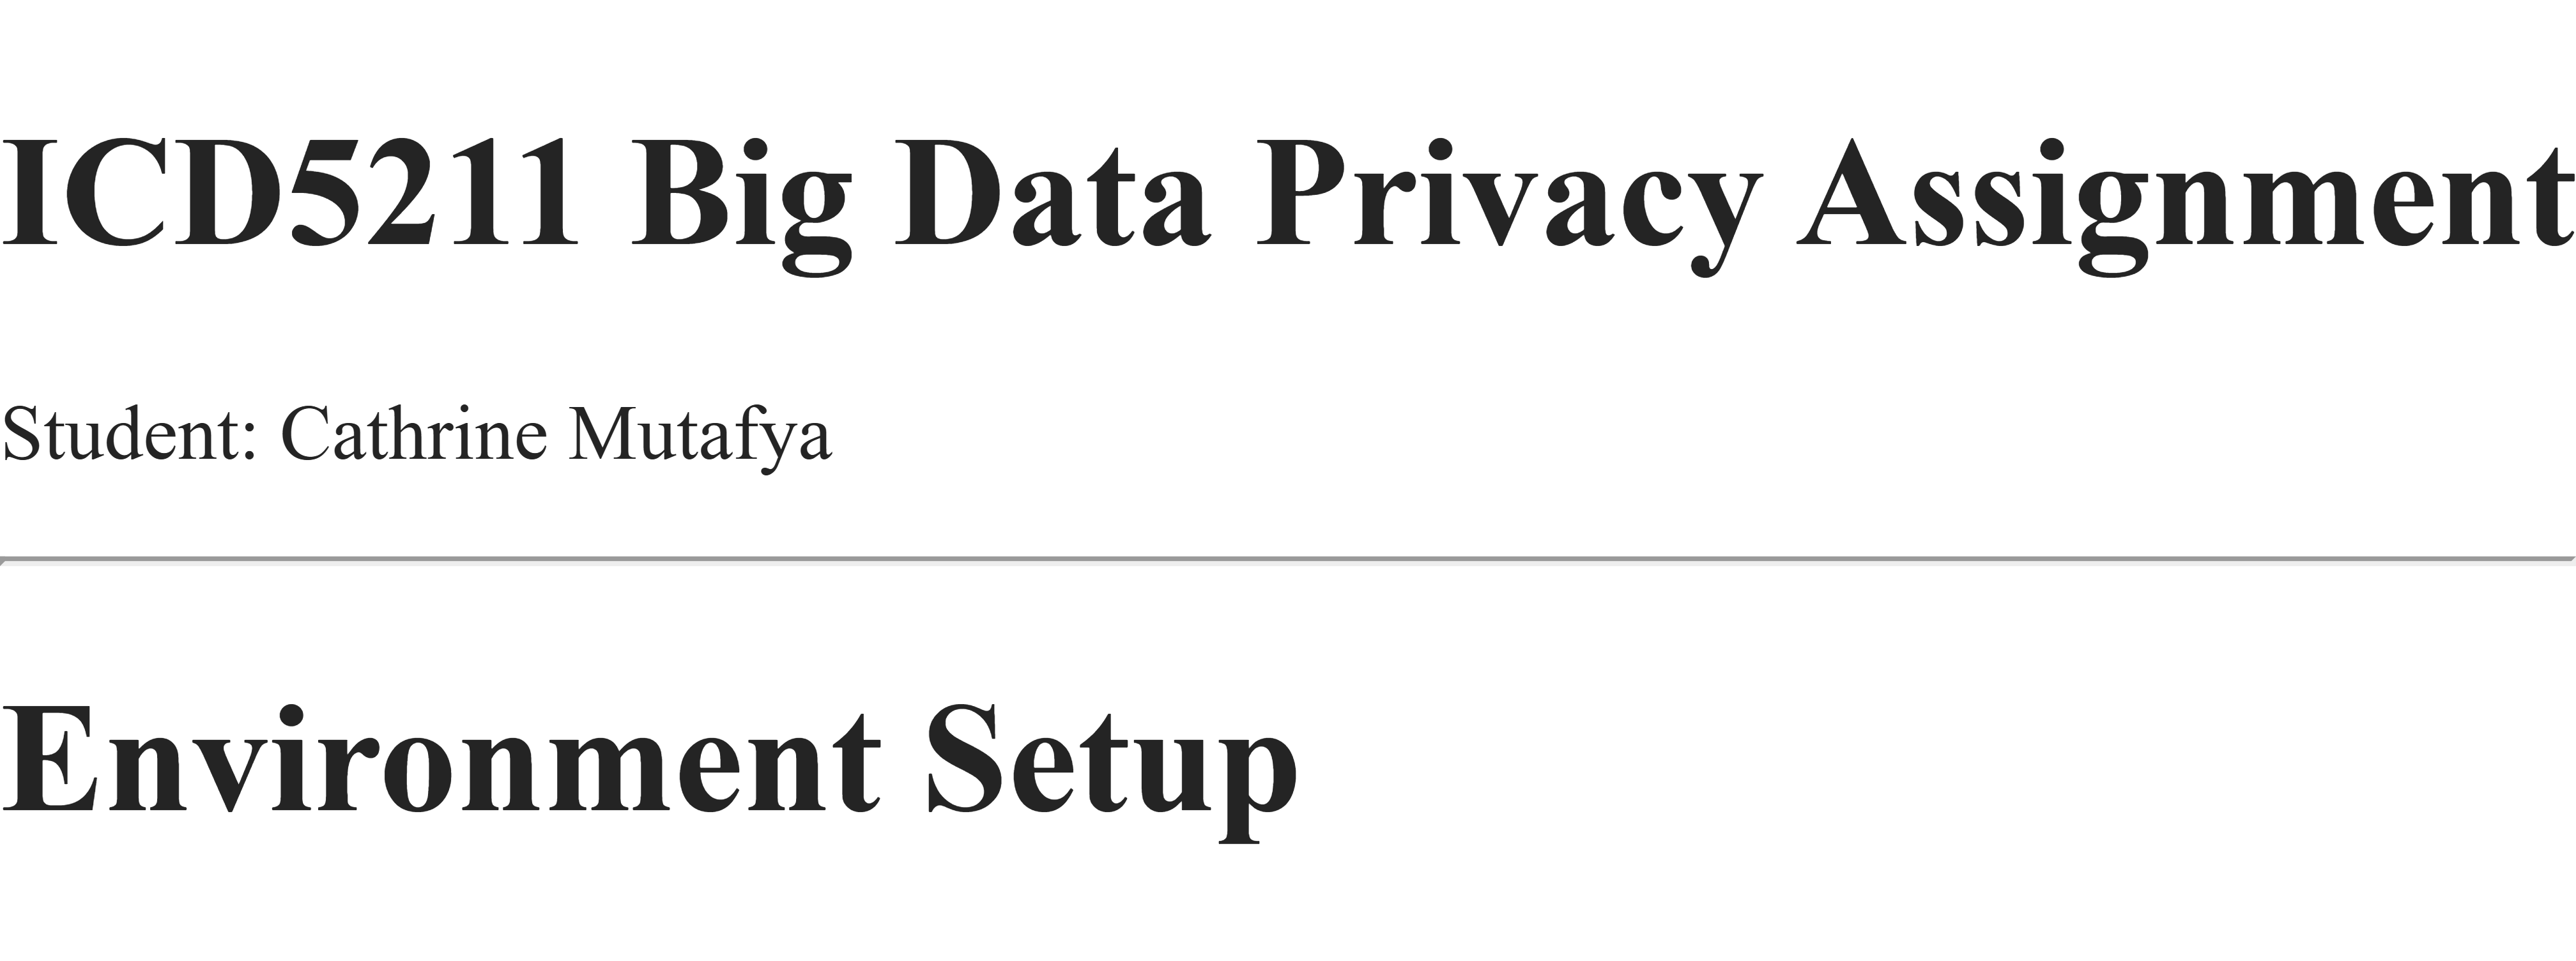

ICD5211 BIG DATA PRIVACY ASSIGNMENT

0. Environment Setup

1. Data Loading

Q1 System Architecture, Profiling and Data Contract

Q2 Protection Controls and Validation

Q3 De-Identification Analysis

Q4 Synthetic Data Evaluation

Q5 Differential Privacy

Q6 Federated Analytics

Conclusions

References


In [184]:
# Environment Setup

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment ready")

Environment ready


In [185]:
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset Loaded Successfully")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Saving Synthetic_TymeBank_Host_Data_500_Rows.csv to Synthetic_TymeBank_Host_Data_500_Rows (1).csv
Dataset Loaded Successfully
Rows: 500
Columns: 149


,HPAN,ACCT1,ACCT1TP,ACCT2,ACCT2TP,ACCT2_CURRENCY,ACCTBAL,ACCTBAL2,ACQINSTCC,ACQINSTID,...,TIME,TRACE,TRACK1,TRACK2,TRANS_STAT,TRANS_TYPE,TTIME,UDATE,UTRNNO,ACCT_NO
0,999999XXXXXX0157,99000000157,101,NaN,0,0,313901,0,710,479050,...,100600,1,NaN,NaN,DECLINED,700,100600,20261012,800000001,99000000157
1,999999XXXXXX0027,99000000027,101,NaN,0,0,88089,0,710,478795,...,100700,2,NaN,NaN,SUCCESS,712,100700,20261012,800000002,99000000027
2,999999XXXXXX0102,99000000102,101,NaN,0,0,217472,0,710,478795,...,100800,3,NaN,NaN,SUCCESS,774,100800,20261012,800000003,99000000102
3,999999XXXXXX0007,99000000007,101,NaN,0,0,35490,0,710,479050,...,62312,4,NaN,NaN,DECLINED,774,62312,20260927,800000004,99000000007
4,999999XXXXXX0038,99000000038,101,NaN,0,0,188289,0,710,478795,...,24434,5,NaN,NaN,SUCCESS,774,24434,20261012,800000005,99000000038


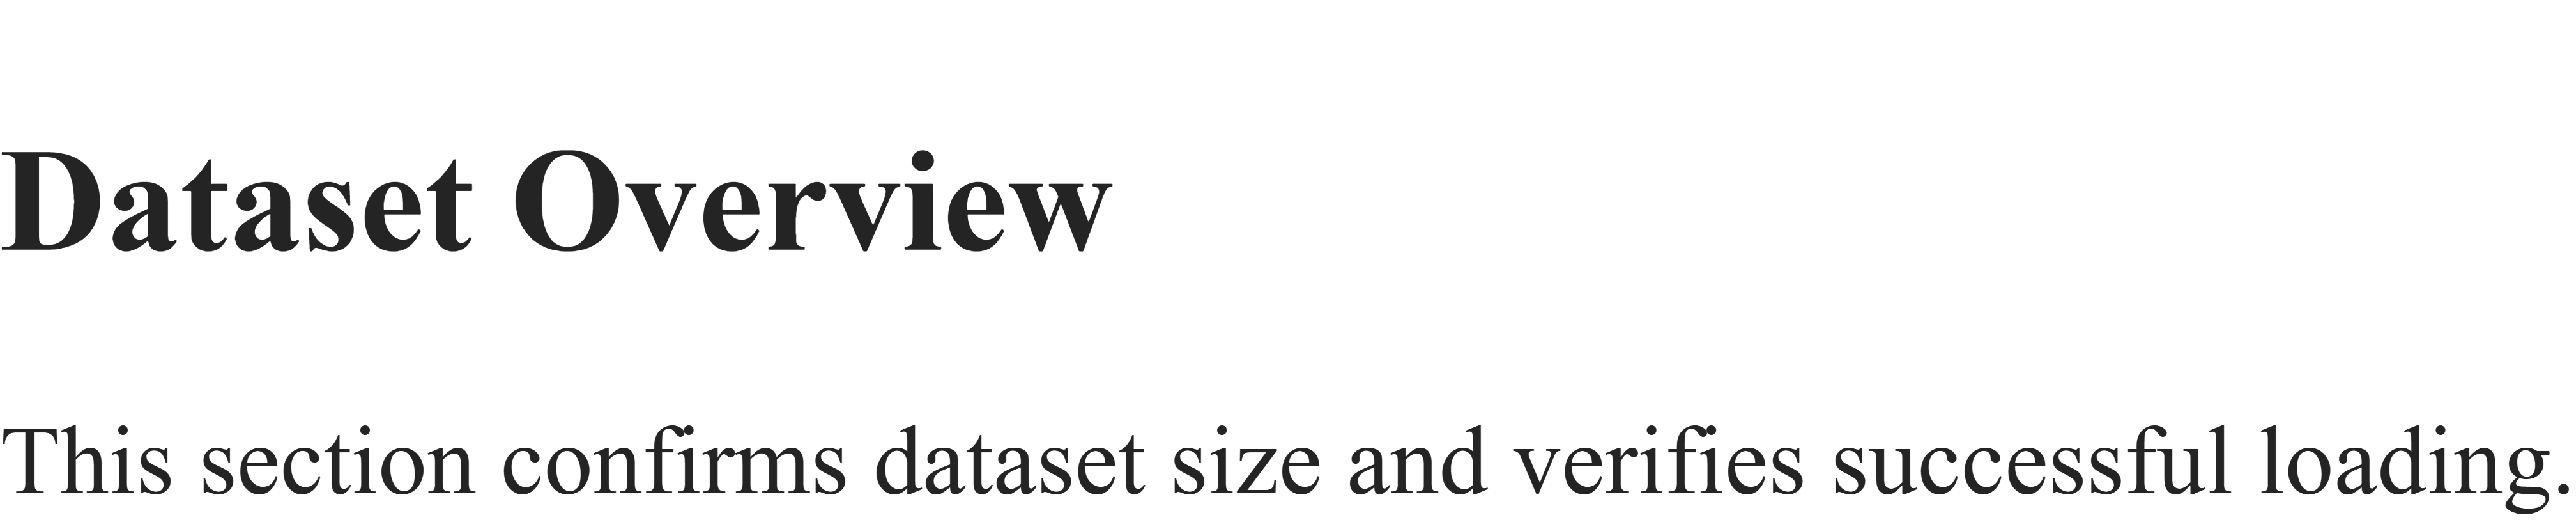

In [186]:
shape_df = pd.DataFrame({
    "Metric":["Rows","Columns"],
    "Value":[df.shape[0], df.shape[1]]
})

shape_df

,Metric,Value
0,Rows,500
1,Columns,149


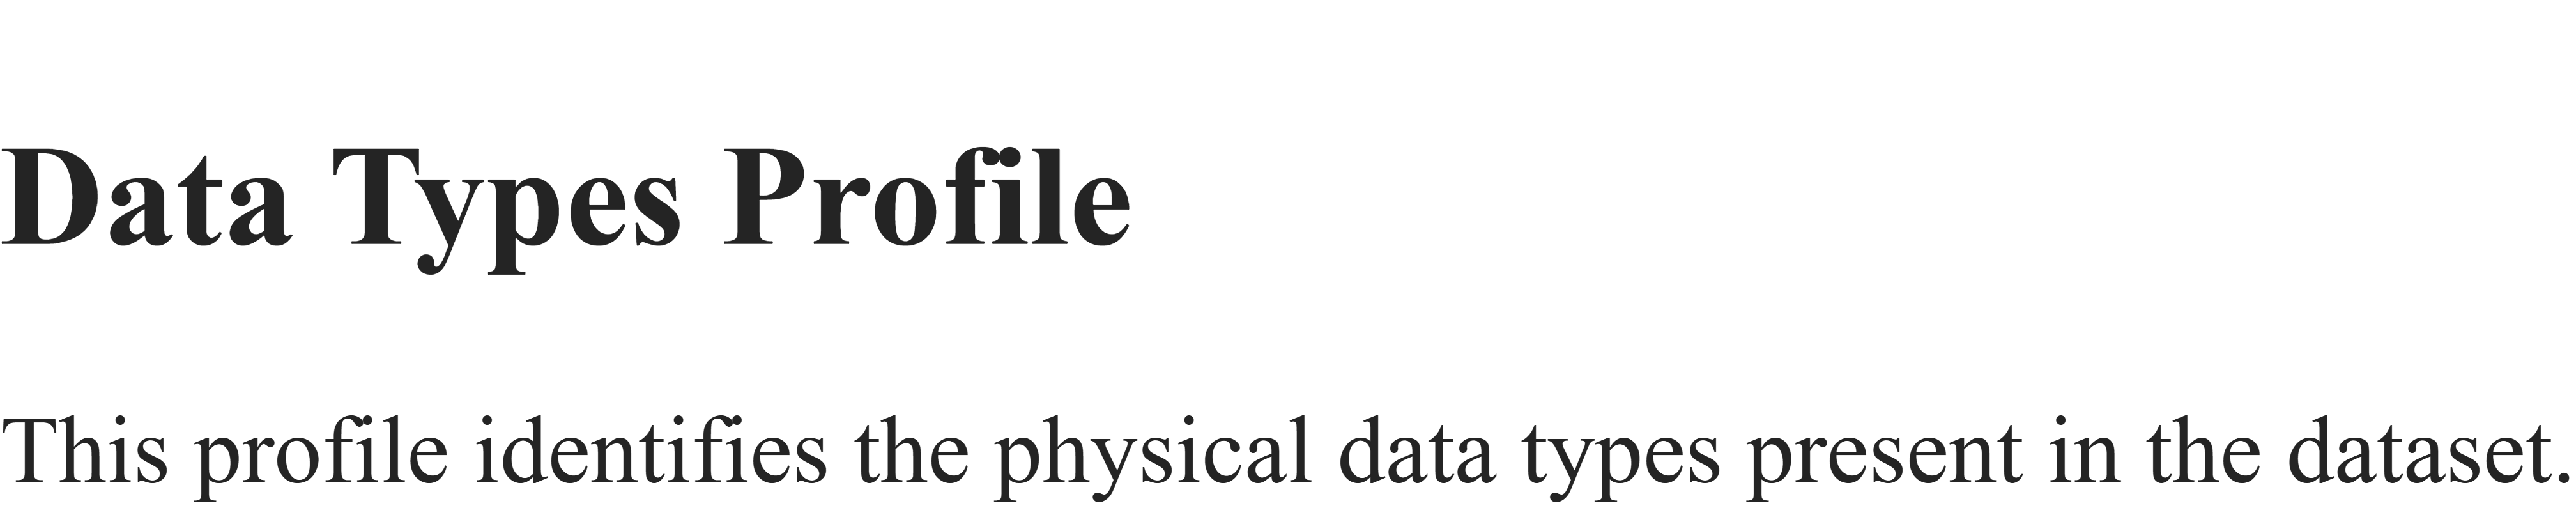

In [187]:
datatype_profile = pd.DataFrame({
    "Column": df.columns,
    "Datatype": df.dtypes.astype(str)
})

datatype_profile

,Column,Datatype
HPAN,HPAN,object
ACCT1,ACCT1,int64
ACCT1TP,ACCT1TP,int64
ACCT2,ACCT2,float64
ACCT2TP,ACCT2TP,int64
...,...,...
TRANS_TYPE,TRANS_TYPE,int64
TTIME,TTIME,int64
UDATE,UDATE,int64
UTRNNO,UTRNNO,int64


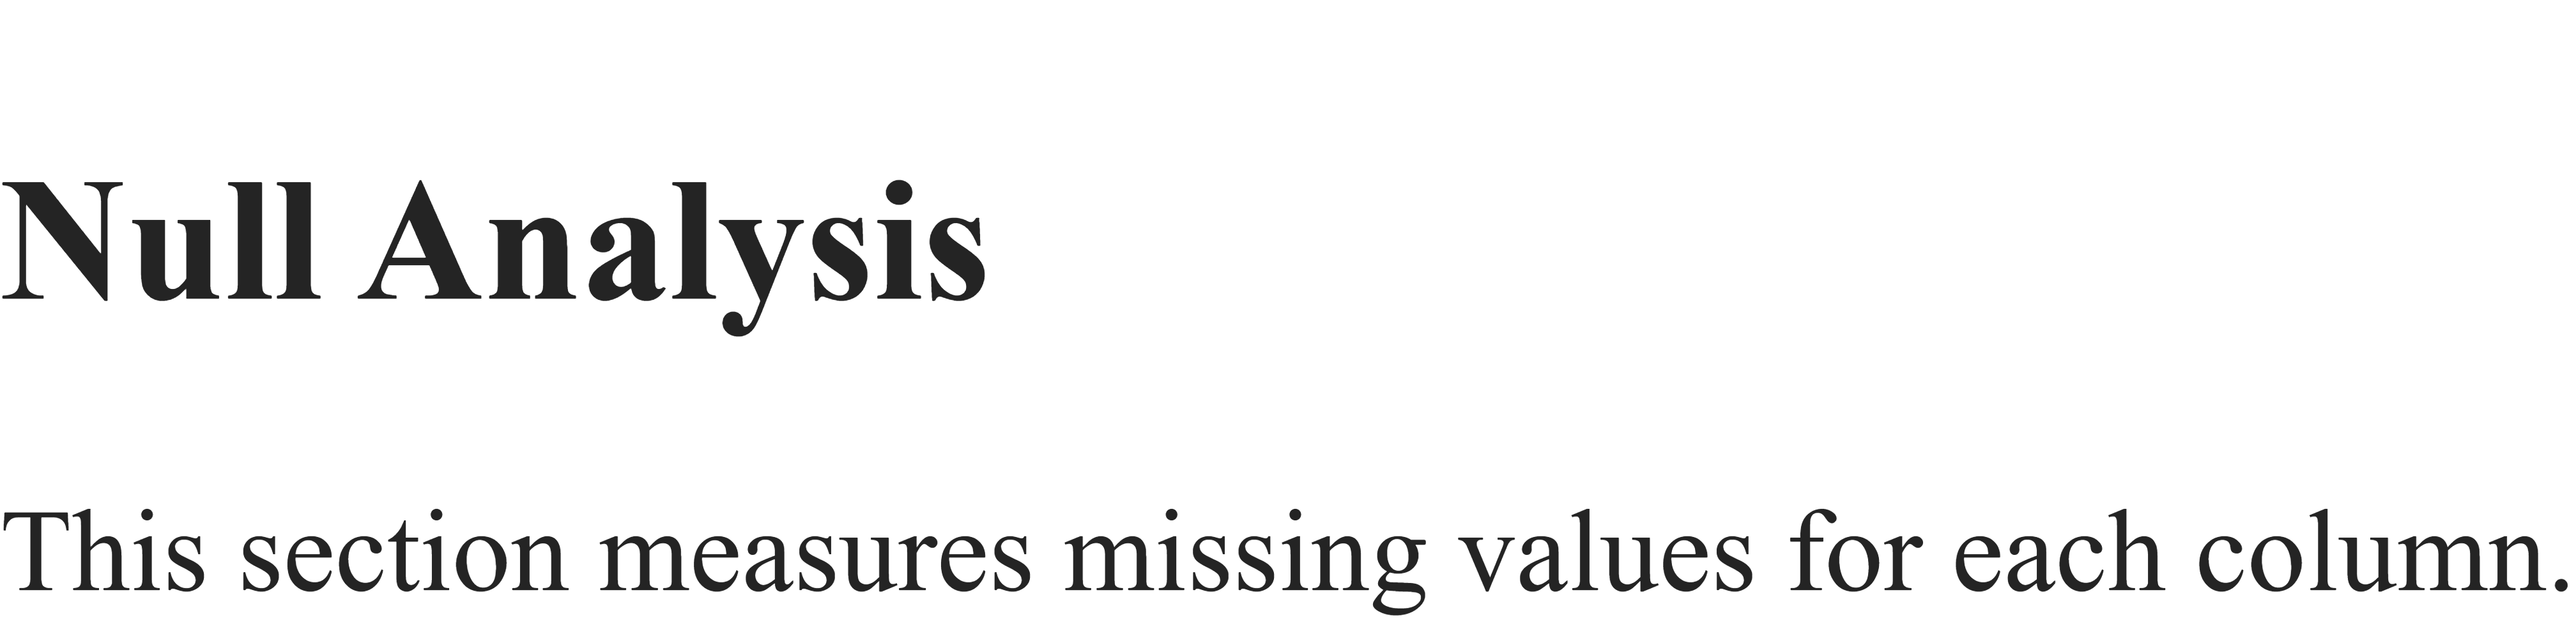

In [188]:
null_profile = pd.DataFrame({
    "Column": df.columns,
    "Null_Count": df.isnull().sum(),
    "Null_Percent": round(df.isnull().mean()*100,2)
})

null_profile = null_profile.sort_values(
    by="Null_Count",
    ascending=False
)

null_profile.head(20)

,Column,Null_Count,Null_Percent
ACCT2,ACCT2,500,100.0
ADDLAMT,ADDLAMT,500,100.0
ADDLDATA,ADDLDATA,500,100.0
ADDRESS_POSTAL_CODE,ADDRESS_POSTAL_CODE,500,100.0
ADDRESS_STATE,ADDRESS_STATE,500,100.0
NETDATA,NETDATA,500,100.0
ORGDEV,ORGDEV,500,100.0
ORGDATA,ORGDATA,500,100.0
HEADER,HEADER,500,100.0
FINAL_STAT,FINAL_STAT,500,100.0


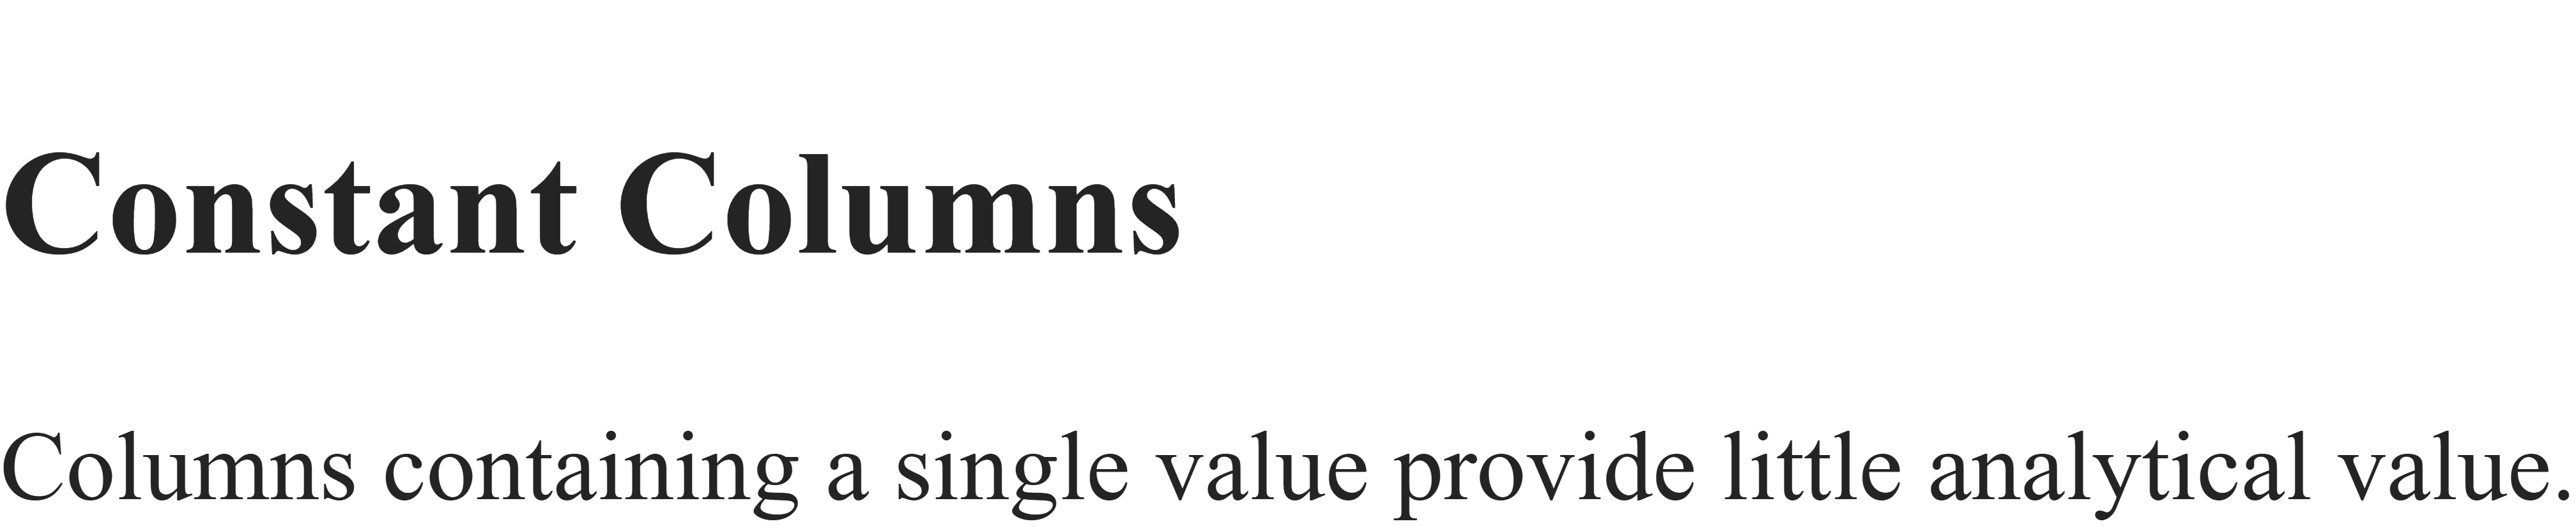

In [189]:
constant_cols = []

for col in df.columns:
    if df[col].nunique(dropna=False) == 1:
        constant_cols.append(col)

print("Number of Constant Columns:", len(constant_cols))

pd.DataFrame({
    "Constant Columns": constant_cols
})

Number of Constant Columns: 104


,Constant Columns
0,ACCT1TP
1,ACCT2
2,ACCT2TP
3,ACCT2_CURRENCY
4,ACCTBAL2
...,...
99,SYSRATE
100,SYS_CURRENCY
101,TDATE
102,TRACK1


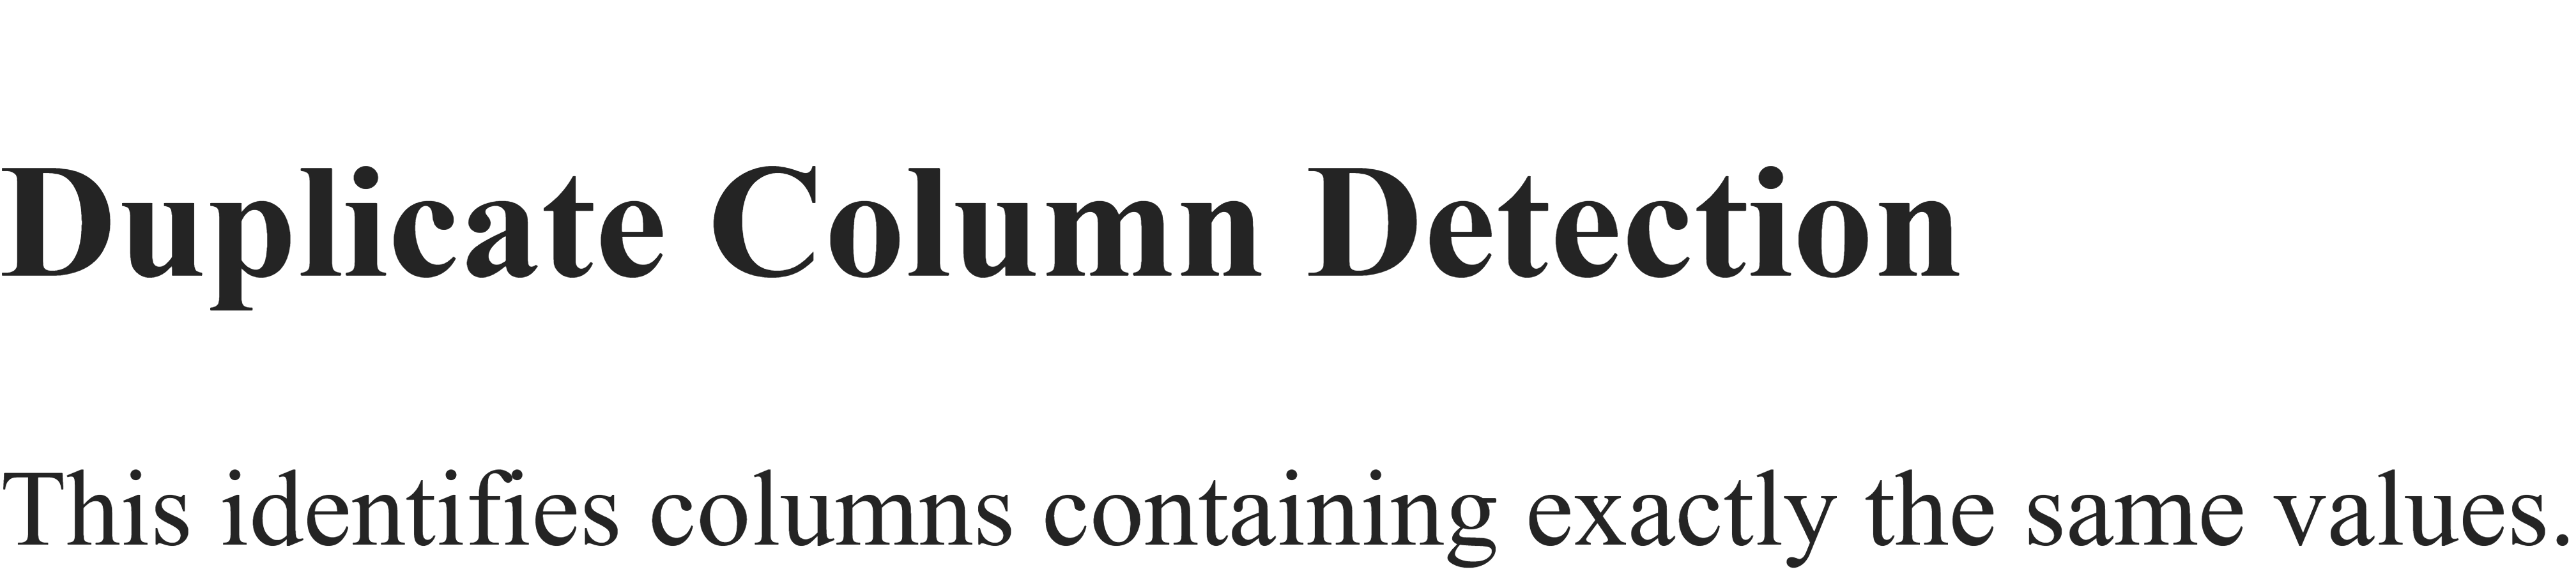

In [190]:
duplicate_columns = []

for i in range(len(df.columns)):
    for j in range(i+1, len(df.columns)):

        col1 = df.columns[i]
        col2 = df.columns[j]

        if df[col1].equals(df[col2]):
            duplicate_columns.append((col1,col2))

duplicate_df = pd.DataFrame(
    duplicate_columns,
    columns=["Column_1","Column_2"]
)

duplicate_df

,Column_1,Column_2
0,ACCT1,ACCT_NO
1,ACCT2,ADDLAMT
2,ACCT2,ADDLDATA
3,ACCT2,ADDRESS_POSTAL_CODE
4,ACCT2,ADDRESS_STATE
...,...,...
1829,SW_CONVDATE,TDATE
1830,SW_CONVERTRATE,SYSRATE
1831,SW_CURRENCY,SYS_CURRENCY
1832,TIME,TTIME


In [191]:
if "REFNUM" in df.columns:

    total_rows = len(df)

    unique_refnum = df["REFNUM"].nunique()

    uniqueness_rate = round(
        unique_refnum/total_rows*100,
        2
    )

    transaction_uniqueness = pd.DataFrame({
        "Metric":[
            "Total Rows",
            "Unique REFNUM",
            "Uniqueness Rate (%)"
        ],
        "Value":[
            total_rows,
            unique_refnum,
            uniqueness_rate
        ]
    })

    display(transaction_uniqueness)


,Metric,Value
0,Total Rows,500.0
1,Unique REFNUM,500.0
2,Uniqueness Rate (%),100.0


In [192]:
identifier_fields = [
    "REFNUM",
    "HPAN",
    "ACCT1",
    "ACCT_NO"
]

results = []

for col in identifier_fields:

    if col in df.columns:

        results.append({
            "Field": col,
            "Unique Values": df[col].nunique(),
            "Repeated Values":
                len(df)-df[col].nunique()
        })

identifier_profile = pd.DataFrame(results)

identifier_profile

,Field,Unique Values,Repeated Values
0,REFNUM,500,0
1,HPAN,157,343
2,ACCT1,157,343
3,ACCT_NO,157,343


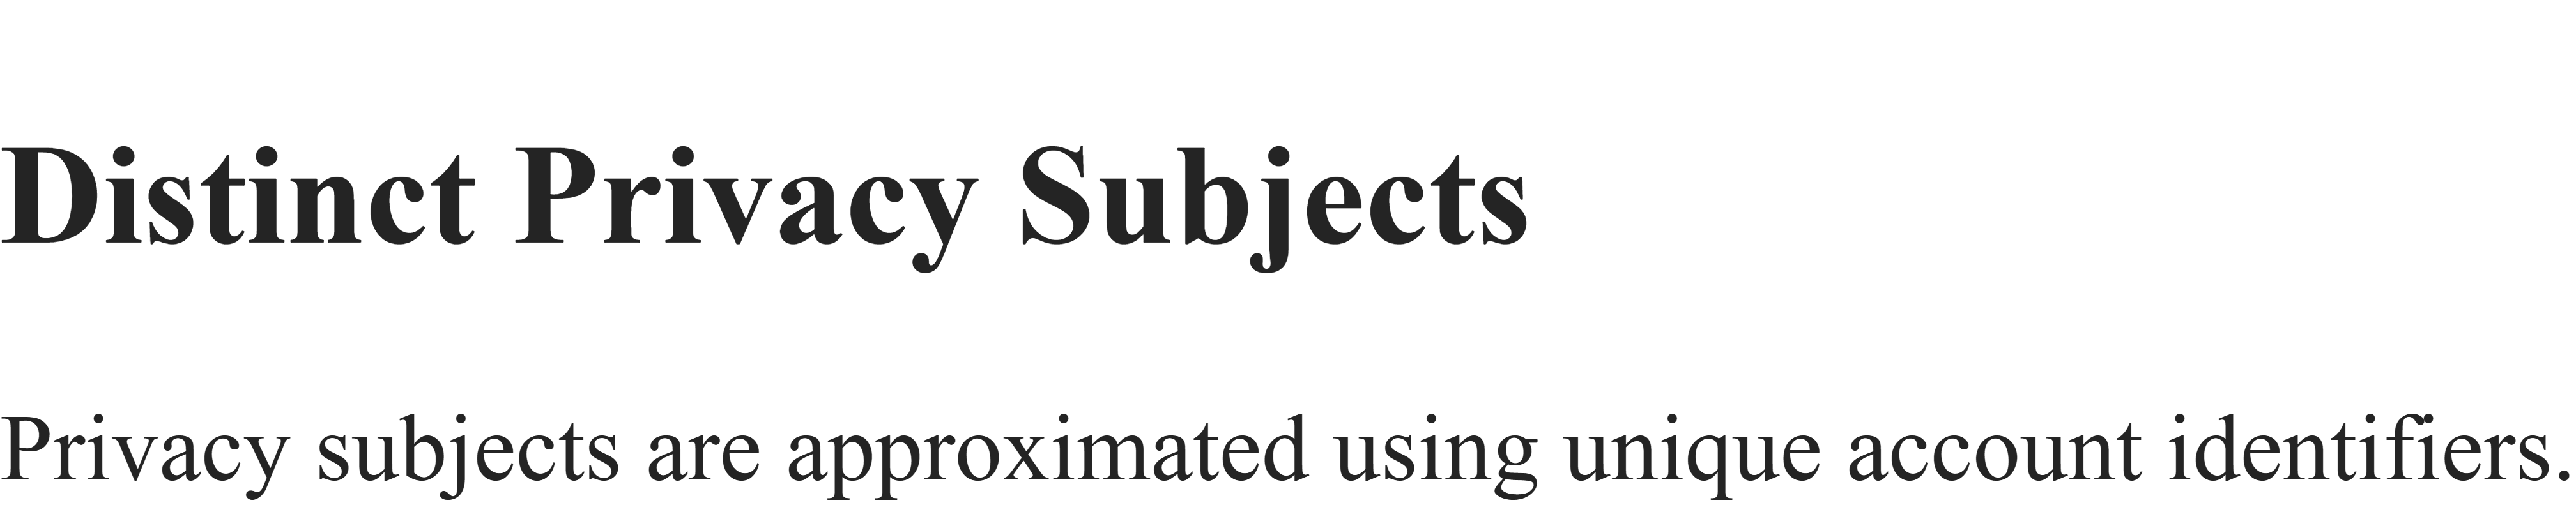

In [193]:
if "ACCT_NO" in df.columns:

    unique_accounts = df["ACCT_NO"].nunique()

elif "ACCT1" in df.columns:

    unique_accounts = df["ACCT1"].nunique()

else:

    unique_accounts = None

print("Distinct Accounts:", unique_accounts)

Distinct Accounts: 157


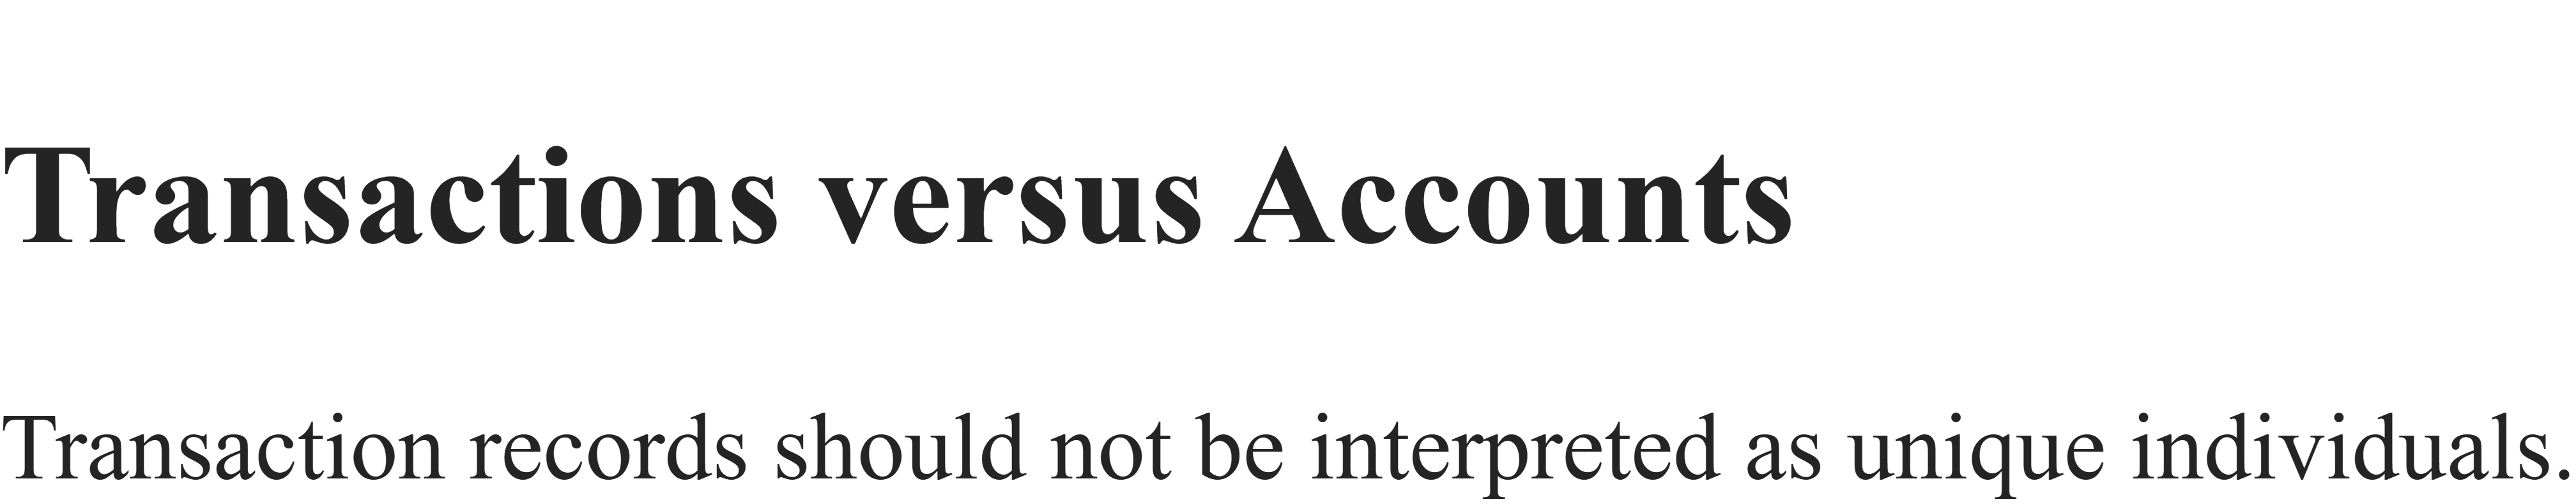

In [194]:
comparison = pd.DataFrame({
    "Metric":[
        "Transaction Records",
        "Distinct Accounts"
    ],
    "Value":[
        len(df),
        unique_accounts
    ]
})

comparison

,Metric,Value
0,Transaction Records,500
1,Distinct Accounts,157


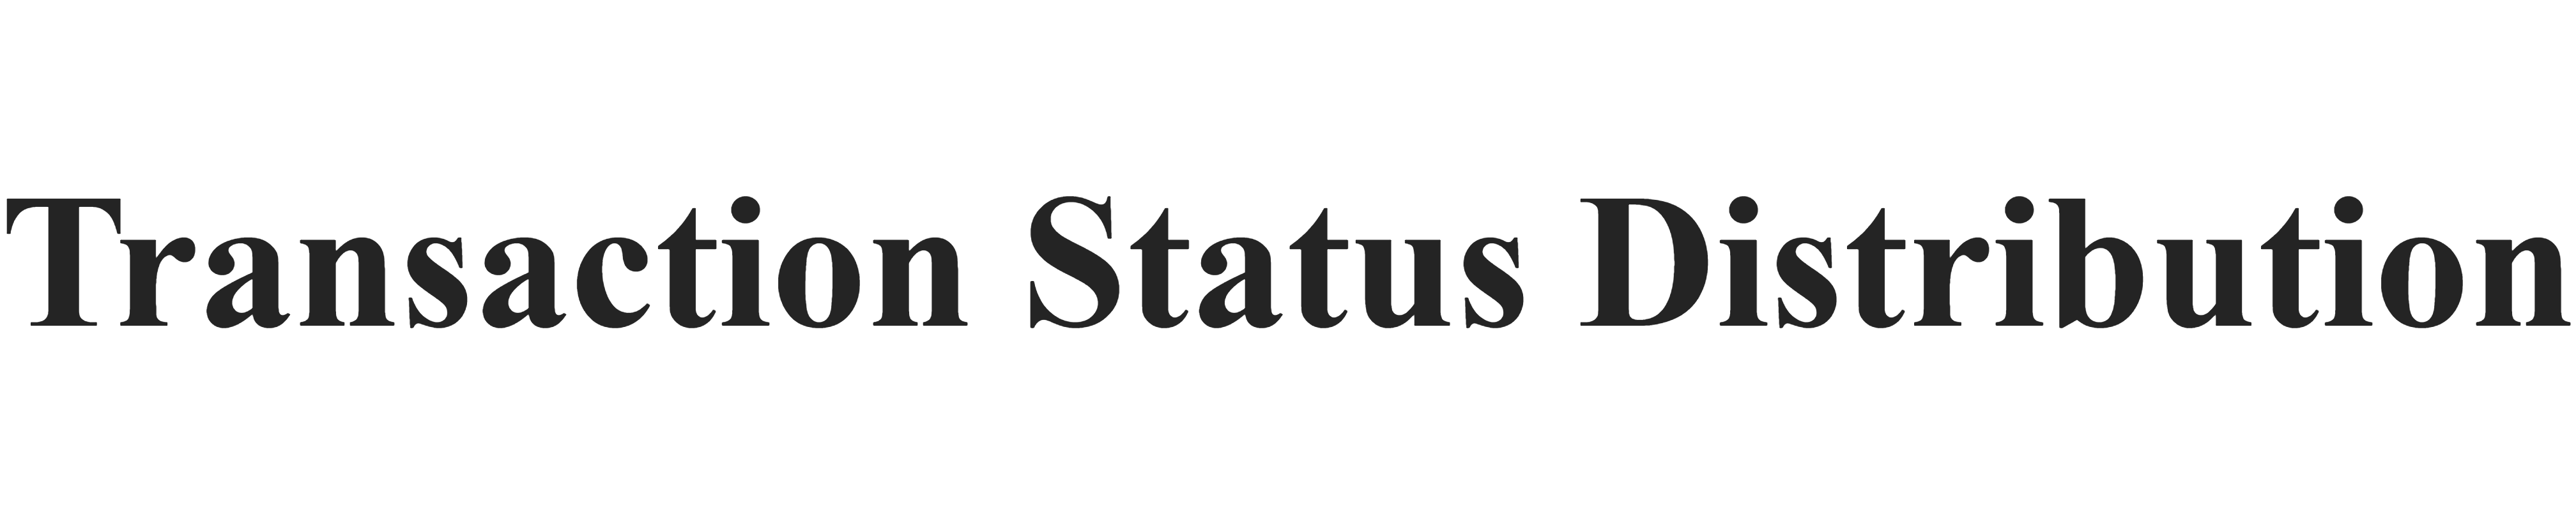

In [195]:
if "TRANS_STAT" in df.columns:

    status_distribution = (
        df["TRANS_STAT"]
        .value_counts(dropna=False)
        .reset_index()
    )

    status_distribution.columns = [
        "TRANS_STAT",
        "COUNT"
    ]

    display(status_distribution)

,TRANS_STAT,COUNT
0,SUCCESS,369
1,DECLINED,131


In [196]:
if "REVERSAL" in df.columns:

    reversal_distribution = (
        df["REVERSAL"]
        .value_counts(dropna=False)
        .reset_index()
    )

    reversal_distribution.columns = [
        "REVERSAL",
        "COUNT"
    ]

    display(reversal_distribution)

,REVERSAL,COUNT
0,0,482
1,1,18


In [197]:
if "RESPCODE" in df.columns:

    response_distribution = (
        df["RESPCODE"]
        .value_counts(dropna=False)
        .reset_index()
    )

    response_distribution.columns = [
        "RESPCODE",
        "COUNT"
    ]

    display(response_distribution)

,RESPCODE,COUNT
0,0,369
1,51,48
2,5,45
3,96,24
4,55,14


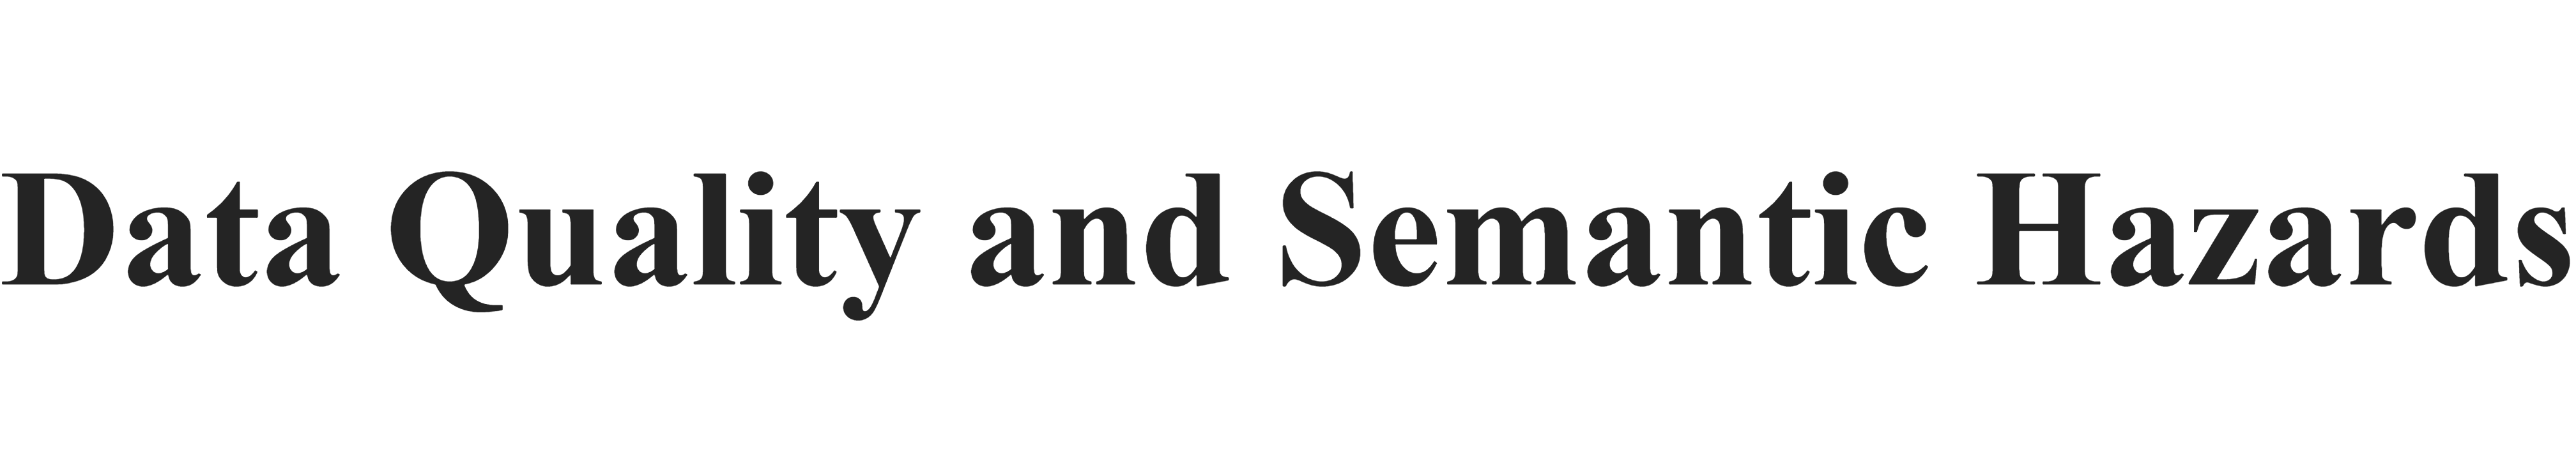

In [198]:
hazards = [
    "Missing values may exist.",
    "Constant columns may exist.",
    "Duplicate columns may exist.",
    "Repeated account identifiers may cause linkability.",
    "Masked card identifiers remain linkable.",
    "No authoritative business dictionary supplied.",
    "Amount units are not documented.",
    "Encoded fields may have uncertain meaning."
]

for i,h in enumerate(hazards,1):
    print(f"{i}. {h}")

1. Missing values may exist.
2. Constant columns may exist.
3. Duplicate columns may exist.
4. Repeated account identifiers may cause linkability.
5. Masked card identifiers remain linkable.
6. No authoritative business dictionary supplied.
7. Amount units are not documented.
8. Encoded fields may have uncertain meaning.


In [199]:
assert df.shape[0] > 0
assert df.shape[1] > 0

print("✅ Positive Test Passed")

✅ Positive Test Passed


In [200]:
try:
    df["FAKE_COLUMN"]
except KeyError:
    print("✅ Adversarial Test Passed")

✅ Adversarial Test Passed


In [201]:
summary_profile = pd.DataFrame({
    "Metric":[
        "Rows",
        "Columns",
        "Successful Transactions",
        "Declined Transactions",
        "Reversals",
        "Non-Reversals",
        "Distinct Accounts"
    ],
    "Value":[
        len(df),
        len(df.columns),
        369,
        131,
        18,
        482,
        unique_accounts
    ]
})

display(summary_profile)


,Metric,Value
0,Rows,500
1,Columns,149
2,Successful Transactions,369
3,Declined Transactions,131
4,Reversals,18
5,Non-Reversals,482
6,Distinct Accounts,157


                                SOURCE CSV
                                     |
                            Ingestion Service
                                     |
                    =================================
                    TRUST BOUNDARY 1 (INGESTION)
                    =================================
                                     |
                              BRONZE ZONE
                          (Raw Immutable Data)
                                     |
                             Validation Engine
                                     |
                    +----------------+----------------+
                    |                                 |
              QUARANTINE                      Valid Records
           (Invalid Records)                        |
                                                    |
                                    ==============================
                                    TRUST BOUNDARY 2 (PRIVACY)
                                    ==============================
                                                    |
                                            HMAC Tokenisation
                                                    |
                                               Token Vault
                                               Encryption
                                                    |
                                               SILVER ZONE
                                      (Cleaned & Tokenised Data)
                                                    |
                                    Account-Level Aggregation
                                                    |
                                                GOLD ZONE
                                       (Analytics & Metrics)
                                                    |
                                    =========================
                                    TRUST BOUNDARY 3 (RELEASE)
                                    =========================
                                                    |
                       +----------------+-------------------+
                       |                                    |
                Internal Reports                 Approved Release
                                                         |
                                          Differential Privacy
                                                         |
                                             External Consumers
                                                         |
                                               Secure Deletion

Audit Logging ----------> All Layers
KMS / Key Vault --------> Encryption Keys
IAM / RBAC -------------> Access Control

In [202]:
architecture_components = pd.DataFrame({
    "Component": [
        "Source CSV",
        "Bronze Zone",
        "Validation Engine",
        "Quarantine Zone",
        "Token Vault",
        "Silver Zone",
        "Aggregation Engine",
        "Gold Zone",
        "Release Layer",
        "Deletion Service"
    ],
    "Purpose": [
        "Original transaction records",
        "Raw immutable storage",
        "Data quality checks",
        "Invalid record storage",
        "HMAC token storage",
        "Clean and tokenised data",
        "Account-level metrics",
        "Curated analytics",
        "Approved outputs",
        "Retention management"
    ]
})

architecture_components

,Component,Purpose
0,Source CSV,Original transaction records
1,Bronze Zone,Raw immutable storage
2,Validation Engine,Data quality checks
3,Quarantine Zone,Invalid record storage
4,Token Vault,HMAC token storage
5,Silver Zone,Clean and tokenised data
6,Aggregation Engine,Account-level metrics
7,Gold Zone,Curated analytics
8,Release Layer,Approved outputs
9,Deletion Service,Retention management


In [203]:
architecture_components.to_csv(
    "architecture_components.csv",
    index=False
)

print("architecture_components.csv saved successfully")

architecture_components.csv saved successfully


In [204]:
# Install graphviz

!apt-get -qq install graphviz
!pip -q install graphviz

print("Environment ready")

Environment ready


In [205]:
from graphviz import Digraph

g = Digraph("MosiPay")

g.attr(rankdir="LR")

g.node("SRC","Source Data\n149 Fields")

g.node("ING","Ingestion")

g.node("Q","Quarantine")

g.node("B","Bronze\nRaw Storage")

g.node("S","Silver\nValidated Data")

g.node("AGG","Account-Level\nAggregation")

g.node("G","Gold\nAnalytics")

g.node("REL","Controlled\nRelease")

g.node("CONS","Consumers")

g.node("TV","Token Vault")

g.node("KMS","Key Boundary")

g.node("LOG","Audit Logs")

g.node("DEL","Deletion")

g.edge("SRC","ING")
g.edge("ING","Q","Invalid")
g.edge("ING","B","Valid")

g.edge("B","S")
g.edge("S","AGG")
g.edge("AGG","G")
g.edge("G","REL")
g.edge("REL","CONS")

g.edge("B","TV")
g.edge("TV","KMS")

g.edge("B","LOG")
g.edge("S","LOG")
g.edge("G","LOG")

g.edge("G","DEL")

g.render("mosipay_architecture",
         format="png",
         cleanup=True)

print("Architecture Diagram Generated")

Architecture Diagram Generated


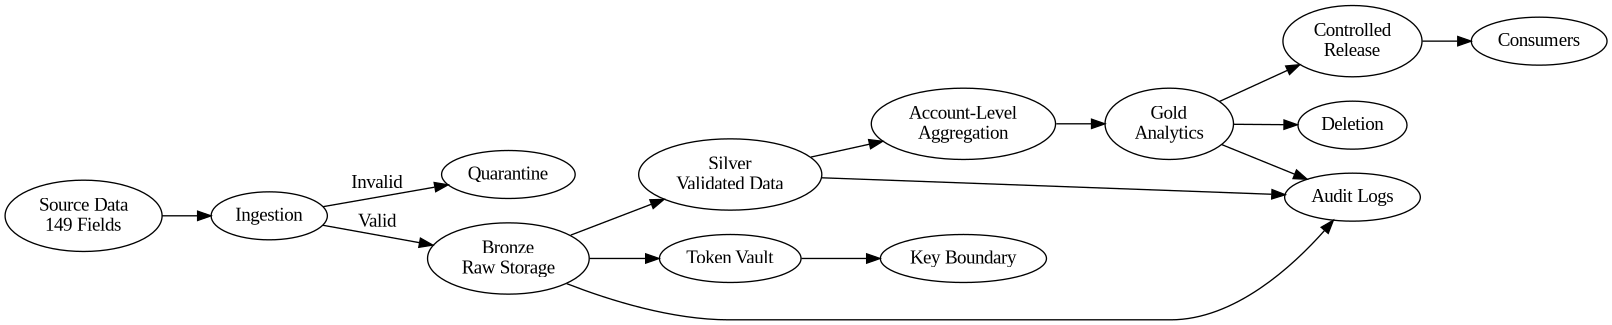

In [206]:
from IPython.display import Image

Image("mosipay_architecture.png")

In [207]:
from graphviz import Digraph
from IPython.display import Image

g = Digraph("MosiPay")
g.attr(rankdir="LR")

# ------------------------------
# TRUST BOUNDARY 1
# INGESTION BOUNDARY
# ------------------------------

with g.subgraph(name="cluster_1") as c:
    c.attr(label="Trust Boundary 1 - Ingestion Boundary")
    c.attr(color="blue")

    c.node("SRC","Source Data\n149 Fields")
    c.node("ING","Ingestion")
    c.node("Q","Quarantine")
    c.node("B","Bronze\nRaw Storage")

# ------------------------------
# TRUST BOUNDARY 2
# PRIVACY BOUNDARY
# ------------------------------

with g.subgraph(name="cluster_2") as c:
    c.attr(label="Trust Boundary 2 - Privacy Boundary")
    c.attr(color="red")

    c.node("S","Silver\nValidated Data")
    c.node("TV","Token Vault")
    c.node("KB","Key Boundary")
    c.node("AGG","Account-Level\nAggregation")

# ------------------------------
# TRUST BOUNDARY 3
# RELEASE BOUNDARY
# ------------------------------

with g.subgraph(name="cluster_3") as c:
    c.attr(label="Trust Boundary 3 - Release Boundary")
    c.attr(color="green")

    c.node("G","Gold Analytics")
    c.node("CR","Controlled Release")
    c.node("C","Consumers")

# Shared services

g.node("LOG","Audit Logs")
g.node("DEL","Deletion")

# Flows

g.edge("SRC","ING")

g.edge("ING","Q",label="Invalid")

g.edge("ING","B",label="Valid")

g.edge("B","S")

g.edge("S","AGG")

g.edge("AGG","G")

g.edge("G","CR")

g.edge("CR","C")

g.edge("B","TV")

g.edge("TV","KB")

# Logging

g.edge("B","LOG")

g.edge("S","LOG")

g.edge("G","LOG")

# Deletion

g.edge("G","DEL")

g.render("trust_boundary_architecture",
         format="png",
         cleanup=True)

print("Trust Boundary Architecture Generated")

Trust Boundary Architecture Generated


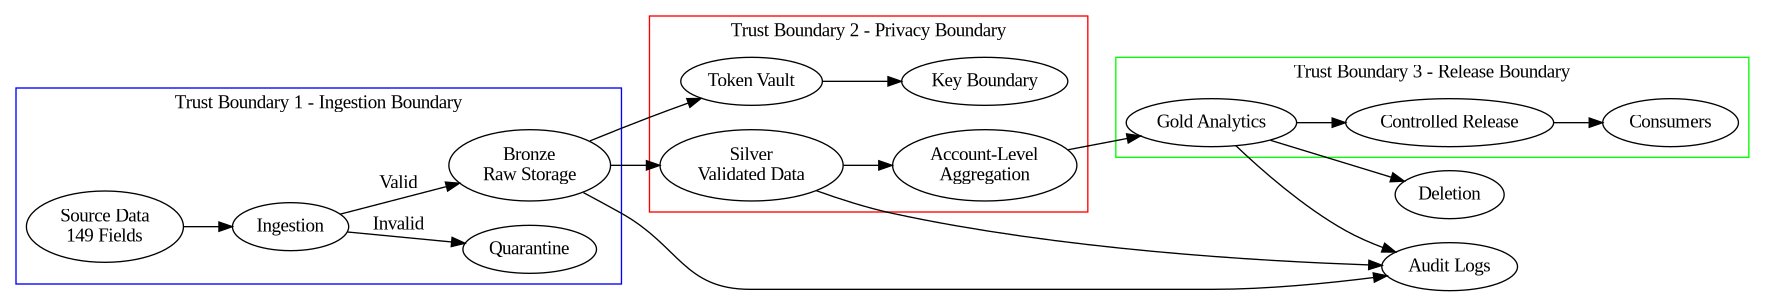

In [208]:
Image("trust_boundary_architecture.png")

In [209]:
import pandas as pd

trust_boundaries = pd.DataFrame({
    "Trust Boundary":[
        "Trust Boundary 1 - Ingestion Boundary",
        "Trust Boundary 2 - Privacy Boundary",
        "Trust Boundary 3 - Release Boundary"
    ],

    "Components":[
        "Source Data, Ingestion, Quarantine, Bronze",
        "Silver, Token Vault, Key Boundary, Aggregation",
        "Gold Analytics, Controlled Release, Consumers"
    ],

    "Purpose":[
        "Separates source systems from processing systems",
        "Separates identifiable data from analytics",
        "Separates internal analytics from external consumers"
    ]
})

trust_boundaries

,Trust Boundary,Components,Purpose
0,Trust Boundary 1 - Ingestion Boundary,"Source Data, Ingestion, Quarantine, Bronze",Separates source systems from processing systems
1,Trust Boundary 2 - Privacy Boundary,"Silver, Token Vault, Key Boundary, Aggregation",Separates identifiable data from analytics
2,Trust Boundary 3 - Release Boundary,"Gold Analytics, Controlled Release, Consumers",Separates internal analytics from external con...


In [210]:
principals = pd.DataFrame({
    "Principal":[
        "Data Provider",
        "Ingestion Service",
        "ETL Service",
        "Security Administrator",
        "Analytics User"
    ],

    "Boundary":[
        "Boundary 1",
        "Boundary 1",
        "Boundary 2",
        "Boundary 2",
        "Boundary 3"
    ],

    "Access":[
        "Submit Data",
        "Validate Data",
        "Transform Data",
        "Manage Keys",
        "Read Approved Outputs"
    ]
})

principals

,Principal,Boundary,Access
0,Data Provider,Boundary 1,Submit Data
1,Ingestion Service,Boundary 1,Validate Data
2,ETL Service,Boundary 2,Transform Data
3,Security Administrator,Boundary 2,Manage Keys
4,Analytics User,Boundary 3,Read Approved Outputs


In [211]:
import pandas as pd

encryption_points = pd.DataFrame({
    "Location":[
        "Source to Ingestion",
        "Bronze Storage",
        "Silver Storage",
        "Gold Storage",
        "Token Vault",
        "Key Boundary"
    ],
    "Protection":[
        "TLS Encryption",
        "Encryption at Rest",
        "Encryption at Rest",
        "Encryption at Rest",
        "Dedicated Encryption Key",
        "Hardware-backed Key Protection"
    ]
})

encryption_points

,Location,Protection
0,Source to Ingestion,TLS Encryption
1,Bronze Storage,Encryption at Rest
2,Silver Storage,Encryption at Rest
3,Gold Storage,Encryption at Rest
4,Token Vault,Dedicated Encryption Key
5,Key Boundary,Hardware-backed Key Protection


In [212]:
# Account-level aggregation using actual dataset

account_summary = (
    df.groupby("ACCT_NO")["ACTAMT"]
      .sum()
      .reset_index()
      .sort_values("ACTAMT", ascending=False)
)

print("Number of Transactions:", len(df))
print("Number of Unique Accounts:", df["ACCT_NO"].nunique())

account_summary.head(10)

Number of Transactions: 500
Number of Unique Accounts: 157


,ACCT_NO,ACTAMT
4,99000000005,549607
30,99000000031,408696
121,99000000126,403247
73,99000000076,300355
47,99000000048,297325
117,99000000122,292272
28,99000000029,281262
67,99000000070,279998
11,99000000012,276175
124,99000000129,271058


In [213]:
import pandas as pd

audit_events = pd.DataFrame({
    "Event":[
        "Data Ingestion",
        "Validation",
        "Quarantine Action",
        "Tokenisation Request",
        "Data Access",
        "Release Approval",
        "Deletion Activity"
    ],

    "Reason Logged":[
        "Track uploaded files",
        "Track validation outcomes",
        "Track rejected records",
        "Track identifier protection",
        "Track user access",
        "Track approved releases",
        "Track retention compliance"
    ]
})

audit_events

,Event,Reason Logged
0,Data Ingestion,Track uploaded files
1,Validation,Track validation outcomes
2,Quarantine Action,Track rejected records
3,Tokenisation Request,Track identifier protection
4,Data Access,Track user access
5,Release Approval,Track approved releases
6,Deletion Activity,Track retention compliance


In [214]:
import pandas as pd

release_controls = pd.DataFrame({
    "Output Type":[
        "Aggregated Statistics",
        "Differentially Private Results",
        "Federated Analytics Results"
    ],
    "Release Decision":[
        "Approved",
        "Approved",
        "Approved"
    ],
    "Reason":[
        "No raw identifiers exposed",
        "Privacy-preserving output",
        "No institution-level raw records shared"
    ]
})

release_controls

,Output Type,Release Decision,Reason
0,Aggregated Statistics,Approved,No raw identifiers exposed
1,Differentially Private Results,Approved,Privacy-preserving output
2,Federated Analytics Results,Approved,No institution-level raw records shared


In [215]:
deletion_controls = pd.DataFrame({
    "Layer":[
        "Bronze",
        "Silver",
        "Gold"
    ],

    "Deletion Action":[
        "Retention-based deletion",
        "Retention-based deletion",
        "Retention-based deletion"
    ],

    "Audit Evidence":[
        "Required",
        "Required",
        "Required"
    ]
})

deletion_controls

,Layer,Deletion Action,Audit Evidence
0,Bronze,Retention-based deletion,Required
1,Silver,Retention-based deletion,Required
2,Gold,Retention-based deletion,Required


In [216]:
cloud_mapping = pd.DataFrame({
    "Function":[
        "Storage",
        "IAM",
        "KMS",
        "Audit Logging"
    ],

    "AWS Proposed":[
        "Amazon S3",
        "AWS IAM",
        "AWS KMS",
        "AWS CloudTrail"
    ],

    "Azure Proposed":[
        "Azure Data Lake Storage Gen2",
        "Microsoft Entra ID",
        "Azure Key Vault",
        "Azure Monitor"
    ]
})

cloud_mapping

,Function,AWS Proposed,Azure Proposed
0,Storage,Amazon S3,Azure Data Lake Storage Gen2
1,IAM,AWS IAM,Microsoft Entra ID
2,KMS,AWS KMS,Azure Key Vault
3,Audit Logging,AWS CloudTrail,Azure Monitor


In [217]:
import pandas as pd

rejected_alternatives = pd.DataFrame({
    "Alternative":[
        "Shared Raw Data Repository",
        "Emailing Filtered CSV Files",
        "Simple Hashing Without Key Management",
        "Direct Source-to-Gold Processing"
    ],

    "Rejected Reason":[
        "Excessive disclosure risk",
        "No technical access control or revocation",
        "Weak key custody and linkage risk",
        "No validation or quarantine controls"
    ],

    "Privacy Impact":[
        "High",
        "High",
        "Medium-High",
        "High"
    ]
})

rejected_alternatives

,Alternative,Rejected Reason,Privacy Impact
0,Shared Raw Data Repository,Excessive disclosure risk,High
1,Emailing Filtered CSV Files,No technical access control or revocation,High
2,Simple Hashing Without Key Management,Weak key custody and linkage risk,Medium-High
3,Direct Source-to-Gold Processing,No validation or quarantine controls,High


In [218]:
import json

data_contract = {

    "REFNUM": {
        "physical_type":"string",
        "semantic_uncertainty":"transaction identifier",
        "classification":"internal",
        "null_handling":"reject",
        "validation":"not_null",
        "purpose":"transaction tracking",
        "access_role":"data_engineer",
        "retention_class":"7_years"
    },

    "HPAN": {
        "physical_type":"string",
        "semantic_uncertainty":"masked card number",
        "classification":"sensitive",
        "null_handling":"reject",
        "validation":"not_null",
        "purpose":"tokenisation",
        "access_role":"privacy_engineer",
        "retention_class":"restricted"
    },

    "ACCT_NO": {
        "physical_type":"string",
        "semantic_uncertainty":"account identifier",
        "classification":"restricted",
        "null_handling":"reject",
        "validation":"not_null",
        "purpose":"account linkage",
        "access_role":"privacy_engineer",
        "retention_class":"restricted"
    },

    "ACCT1": {
        "physical_type":"string",
        "semantic_uncertainty":"account identifier",
        "classification":"restricted",
        "null_handling":"reject",
        "validation":"not_null",
        "purpose":"account linkage",
        "access_role":"privacy_engineer",
        "retention_class":"restricted"
    },

    "ADDRESS_CITY": {
        "physical_type":"string",
        "semantic_uncertainty":"customer location",
        "classification":"quasi_identifier",
        "null_handling":"allow",
        "validation":"string",
        "purpose":"regional analytics",
        "access_role":"analyst",
        "retention_class":"medium"
    },

    "TERMINAL_TYPE": {
        "physical_type":"string",
        "semantic_uncertainty":"channel category",
        "classification":"internal",
        "null_handling":"allow",
        "validation":"string",
        "purpose":"channel reporting",
        "access_role":"analyst",
        "retention_class":"medium"
    },

    "AUTH_START": {
        "physical_type":"datetime",
        "semantic_uncertainty":"authorisation time",
        "classification":"internal",
        "null_handling":"allow",
        "validation":"datetime",
        "purpose":"processing analysis",
        "access_role":"analyst",
        "retention_class":"medium"
    },

    "SWITCH_DATE": {
        "physical_type":"datetime",
        "semantic_uncertainty":"switch processing date",
        "classification":"internal",
        "null_handling":"allow",
        "validation":"datetime",
        "purpose":"trend analysis",
        "access_role":"analyst",
        "retention_class":"medium"
    },

    "REQAMT": {
        "physical_type":"numeric",
        "semantic_uncertainty":"requested amount unit undocumented",
        "classification":"financial",
        "null_handling":"reject",
        "validation":"non_negative",
        "purpose":"analytics",
        "access_role":"analyst",
        "retention_class":"7_years"
    },

    "ACTAMT": {
        "physical_type":"numeric",
        "semantic_uncertainty":"actual amount unit undocumented",
        "classification":"financial",
        "null_handling":"reject",
        "validation":"non_negative",
        "purpose":"analytics",
        "access_role":"analyst",
        "retention_class":"7_years"
    },

    "TRANS_STAT": {
        "physical_type":"string",
        "semantic_uncertainty":"transaction outcome",
        "classification":"internal",
        "null_handling":"reject",
        "validation":"SUCCESS_DECLINED",
        "purpose":"quality reporting",
        "access_role":"analyst",
        "retention_class":"7_years"
    },

    "RESPCODE": {
        "physical_type":"integer",
        "semantic_uncertainty":"response meaning undocumented",
        "classification":"internal",
        "null_handling":"reject",
        "validation":"numeric",
        "purpose":"response analysis",
        "access_role":"analyst",
        "retention_class":"7_years"
    }
}

with open("data_contract.json","w") as f:
    json.dump(data_contract,f,indent=4)

print("data_contract.json created")

data_contract.json created


In [219]:
import pandas as pd

contract_df = pd.DataFrame(data_contract).T

display(contract_df)

,physical_type,semantic_uncertainty,classification,null_handling,validation,purpose,access_role,retention_class
REFNUM,string,transaction identifier,internal,reject,not_null,transaction tracking,data_engineer,7_years
HPAN,string,masked card number,sensitive,reject,not_null,tokenisation,privacy_engineer,restricted
ACCT_NO,string,account identifier,restricted,reject,not_null,account linkage,privacy_engineer,restricted
ACCT1,string,account identifier,restricted,reject,not_null,account linkage,privacy_engineer,restricted
ADDRESS_CITY,string,customer location,quasi_identifier,allow,string,regional analytics,analyst,medium
TERMINAL_TYPE,string,channel category,internal,allow,string,channel reporting,analyst,medium
AUTH_START,datetime,authorisation time,internal,allow,datetime,processing analysis,analyst,medium
SWITCH_DATE,datetime,switch processing date,internal,allow,datetime,trend analysis,analyst,medium
REQAMT,numeric,requested amount unit undocumented,financial,reject,non_negative,analytics,analyst,7_years
ACTAMT,numeric,actual amount unit undocumented,financial,reject,non_negative,analytics,analyst,7_years


In [220]:
def validate_record(row):

    errors = []

    if pd.isna(row["REFNUM"]):
        errors.append("Missing REFNUM")

    if pd.isna(row["ACCT_NO"]):
        errors.append("Missing ACCT_NO")

    if row["REQAMT"] < 0:
        errors.append("Negative REQAMT")

    if row["ACTAMT"] < 0:
        errors.append("Negative ACTAMT")

    if row["TRANS_STAT"] not in [
        "SUCCESS",
        "DECLINED"
    ]:
        errors.append("Invalid TRANS_STAT")

    return errors

In [221]:
valid_record = df.iloc[0]

errors = validate_record(valid_record)

print("Errors:", errors)

assert len(errors) == 0

print("✅ Positive Test Passed")


Errors: []
✅ Positive Test Passed


In [222]:
bad_record_1 = df.iloc[0].copy()

bad_record_1["ACCT_NO"] = None

errors = validate_record(bad_record_1)

print(errors)

assert "Missing ACCT_NO" in errors

print("✅ Malformed Record Test 1 Passed")


['Missing ACCT_NO']
✅ Malformed Record Test 1 Passed


In [223]:
bad_record_2 = df.iloc[0].copy()

bad_record_2["TRANS_STAT"] = "FRAUD"

errors = validate_record(bad_record_2)

print("Errors:", errors)

assert "Invalid TRANS_STAT" in errors

print("✅ Malformed Record Test 2 Passed")

Errors: ['Invalid TRANS_STAT']
✅ Malformed Record Test 2 Passed


In [224]:
quarantine_records = []

# deliberately add malformed records
test_records = pd.DataFrame([
    bad_record_1,
    bad_record_2
])

for idx, row in test_records.iterrows():

    validation_errors = validate_record(row)

    if len(validation_errors) > 0:

        quarantine_records.append({
            "row_number": idx,
            "errors": ", ".join(validation_errors),
            "decision": "QUARANTINE"
        })

quarantine_df = pd.DataFrame(quarantine_records)

display(quarantine_df)

,row_number,errors,decision
0,0,Missing ACCT_NO,QUARANTINE
1,0,Invalid TRANS_STAT,QUARANTINE


In [225]:
import pandas as pd

risk_register = pd.DataFrame([

{
"Risk_ID":"R1",
"Threat_Actor":"Unauthorised Analyst",
"Entry_Point":"Analytics Environment",
"Asset":"Account Data",
"Likelihood_Impact":"Medium likelihood, high impact due to identifier exposure",
"Preventive_Control":"RBAC and tokenisation",
"Detective_Control":"Audit logging",
"Residual_Risk":"Low",
"Decision_Owner":"Privacy Engineer"
},

{
"Risk_ID":"R2",
"Threat_Actor":"External Attacker",
"Entry_Point":"Raw Storage",
"Asset":"Bronze Data",
"Likelihood_Impact":"Medium likelihood, high impact",
"Preventive_Control":"Encryption at rest",
"Detective_Control":"Storage access monitoring",
"Residual_Risk":"Low",
"Decision_Owner":"Security Lead"
},

{
"Risk_ID":"R3",
"Threat_Actor":"Expired User",
"Entry_Point":"Application Access",
"Asset":"Analytics Reports",
"Likelihood_Impact":"Medium likelihood, medium impact",
"Preventive_Control":"ABAC expiry controls",
"Detective_Control":"Access-denied logging",
"Residual_Risk":"Low",
"Decision_Owner":"IAM Administrator"
},

{
"Risk_ID":"R4",
"Threat_Actor":"Malicious Insider",
"Entry_Point":"Token Vault",
"Asset":"HMAC Keys",
"Likelihood_Impact":"Low likelihood, very high impact",
"Preventive_Control":"KMS protection",
"Detective_Control":"Key-use monitoring",
"Residual_Risk":"Medium",
"Decision_Owner":"Security Lead"
},

{
"Risk_ID":"R5",
"Threat_Actor":"External Recipient",
"Entry_Point":"Released Statistics",
"Asset":"Privacy Subjects",
"Likelihood_Impact":"Medium likelihood, medium impact",
"Preventive_Control":"Aggregation and minimisation",
"Detective_Control":"Release review process",
"Residual_Risk":"Medium",
"Decision_Owner":"Privacy Engineer"
},

{
"Risk_ID":"R6",
"Threat_Actor":"Application Developer",
"Entry_Point":"System Logs",
"Asset":"Sensitive Identifiers",
"Likelihood_Impact":"Medium likelihood, high impact",
"Preventive_Control":"Payload-free logging",
"Detective_Control":"Log review",
"Residual_Risk":"Low",
"Decision_Owner":"Audit Manager"
}

])

display(risk_register)

,Risk_ID,Threat_Actor,Entry_Point,Asset,Likelihood_Impact,Preventive_Control,Detective_Control,Residual_Risk,Decision_Owner
0,R1,Unauthorised Analyst,Analytics Environment,Account Data,"Medium likelihood, high impact due to identifi...",RBAC and tokenisation,Audit logging,Low,Privacy Engineer
1,R2,External Attacker,Raw Storage,Bronze Data,"Medium likelihood, high impact",Encryption at rest,Storage access monitoring,Low,Security Lead
2,R3,Expired User,Application Access,Analytics Reports,"Medium likelihood, medium impact",ABAC expiry controls,Access-denied logging,Low,IAM Administrator
3,R4,Malicious Insider,Token Vault,HMAC Keys,"Low likelihood, very high impact",KMS protection,Key-use monitoring,Medium,Security Lead
4,R5,External Recipient,Released Statistics,Privacy Subjects,"Medium likelihood, medium impact",Aggregation and minimisation,Release review process,Medium,Privacy Engineer
5,R6,Application Developer,System Logs,Sensitive Identifiers,"Medium likelihood, high impact",Payload-free logging,Log review,Low,Audit Manager


In [226]:
import pandas as pd
import hashlib
import hmac
import secrets

In [227]:
HMAC_KEY = secrets.token_bytes(32)

print("HMAC key generated")
print("Key length:", len(HMAC_KEY))

HMAC key generated
Key length: 32


In [228]:
def tokenise_account(account_id):

    return hmac.new(
        HMAC_KEY,
        str(account_id).encode(),
        hashlib.sha256
    ).hexdigest()

In [229]:
raw_view = df.copy()

print("Rows:", len(raw_view))
print("Columns:", len(raw_view.columns))

raw_view.head()

Rows: 500
Columns: 149


,HPAN,ACCT1,ACCT1TP,ACCT2,ACCT2TP,ACCT2_CURRENCY,ACCTBAL,ACCTBAL2,ACQINSTCC,ACQINSTID,...,TIME,TRACE,TRACK1,TRACK2,TRANS_STAT,TRANS_TYPE,TTIME,UDATE,UTRNNO,ACCT_NO
0,999999XXXXXX0157,99000000157,101,NaN,0,0,313901,0,710,479050,...,100600,1,NaN,NaN,DECLINED,700,100600,20261012,800000001,99000000157
1,999999XXXXXX0027,99000000027,101,NaN,0,0,88089,0,710,478795,...,100700,2,NaN,NaN,SUCCESS,712,100700,20261012,800000002,99000000027
2,999999XXXXXX0102,99000000102,101,NaN,0,0,217472,0,710,478795,...,100800,3,NaN,NaN,SUCCESS,774,100800,20261012,800000003,99000000102
3,999999XXXXXX0007,99000000007,101,NaN,0,0,35490,0,710,479050,...,62312,4,NaN,NaN,DECLINED,774,62312,20260927,800000004,99000000007
4,999999XXXXXX0038,99000000038,101,NaN,0,0,188289,0,710,478795,...,24434,5,NaN,NaN,SUCCESS,774,24434,20261012,800000005,99000000038


In [230]:
analytics_view = df.copy()

analytics_view["ACCOUNT_TOKEN"] = (
    analytics_view["ACCT_NO"]
    .astype(str)
    .apply(tokenise_account)
)

analytics_view[
    ["ACCT_NO","ACCOUNT_TOKEN"]
].head()


,ACCT_NO,ACCOUNT_TOKEN
0,99000000157,e95b5938cc7f14e8bf1419bc6c091c3894029db37c04ae...
1,99000000027,077e78d121da6d1892fe7ee311b65c9d4bbeb183c64bfd...
2,99000000102,6f3d7e409266a745b338c24b86e29e9fe7725e74fa3a92...
3,99000000007,6559b27a36aa0752d8e589ce3bf34e47f80f6b08a86a8b...
4,99000000038,0dde5ecfb1f52e32ec3374b55c8243e00b35549556e0bd...


In [231]:
columns_to_remove = [
    "ACCT_NO",
    "ACCT1",
    "HPAN"
]

analytics_view = analytics_view.drop(
    columns=[
        c for c in columns_to_remove
        if c in analytics_view.columns
    ]
)

print("Analytics View Created")
print("Columns Remaining:",
      len(analytics_view.columns))

Analytics View Created
Columns Remaining: 147


In [232]:
for col in [
    "ACCT_NO",
    "ACCT1",
    "HPAN"
]:
    print(
        col,
        col in analytics_view.columns
    )

ACCT_NO False
ACCT1 False
HPAN False


In [233]:
sample_account = str(df["ACCT_NO"].iloc[0])

token1 = tokenise_account(sample_account)
token2 = tokenise_account(sample_account)

print("Token 1:")
print(token1)

print("\nToken 2:")
print(token2)

assert token1 == token2

print("\n✅ Deterministic Join Test Passed")

Token 1:
e95b5938cc7f14e8bf1419bc6c091c3894029db37c04ae47668a2a475c8025d8

Token 2:
e95b5938cc7f14e8bf1419bc6c091c3894029db37c04ae47668a2a475c8025d8

✅ Deterministic Join Test Passed


In [234]:
external_release = (
    df.groupby("TRANS_STAT")
      .size()
      .reset_index(name="COUNT")
)

display(external_release)

,TRANS_STAT,COUNT
0,DECLINED,131
1,SUCCESS,369


In [235]:
access_matrix = pd.DataFrame({

    "View":[
        "Raw View",
        "Quarantine View",
        "Analytics View",
        "External Release View"
    ],

    "Access":[
        "Privacy Engineer",
        "Data Engineer",
        "Business Analyst",
        "External Partner"
    ]
})

display(access_matrix)

,View,Access
0,Raw View,Privacy Engineer
1,Quarantine View,Data Engineer
2,Analytics View,Business Analyst
3,External Release View,External Partner


In [236]:
assert "ACCOUNT_TOKEN" in analytics_view.columns

print("✅ Positive Test Passed")

✅ Positive Test Passed


In [237]:
try:
    analytics_view["ACCT_NO"]
except KeyError:
    print("✅ Adversarial Test Passed")

✅ Adversarial Test Passed


In [238]:
!pip install cryptography

In [239]:
import os
import json

from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from cryptography.hazmat.primitives.keywrap import (
    aes_key_wrap,
    aes_key_unwrap
)

In [240]:
record = df.iloc[0].to_dict()

plaintext = json.dumps(record).encode()

print("Record selected")
print("Bytes:", len(plaintext))

Record selected
Bytes: 2744


In [241]:
KEK_V1 = AESGCM.generate_key(
    bit_length=256
)

KEK_V2 = AESGCM.generate_key(
    bit_length=256
)

print("KEK Version 1 Created")
print("KEK Version 2 Created")

KEK Version 1 Created
KEK Version 2 Created


In [242]:
DEK = AESGCM.generate_key(
    bit_length=256
)

print("Fresh DEK Created")

Fresh DEK Created


In [243]:
wrapped_DEK = aes_key_wrap(
    KEK_V1,
    DEK
)

print("Wrapped DEK Length:",
      len(wrapped_DEK))

Wrapped DEK Length: 40


In [244]:
aesgcm = AESGCM(DEK)

nonce = os.urandom(12)

associated_data = (
    b"ICD5211-Q2B-V1"
)

ciphertext = aesgcm.encrypt(
    nonce,
    plaintext,
    associated_data
)

print(
    "Ciphertext Length:",
    len(ciphertext)
)

Ciphertext Length: 2760


In [245]:
unwrapped_DEK = aes_key_unwrap(
    KEK_V1,
    wrapped_DEK
)

aesgcm_dec = AESGCM(
    unwrapped_DEK
)

decrypted = aesgcm_dec.decrypt(
    nonce,
    ciphertext,
    associated_data
)

assert decrypted == plaintext

print(
    "✅ Correct Decryption Passed"
)

✅ Correct Decryption Passed


In [246]:
tampered = bytearray(ciphertext)

tampered[0] ^= 1

try:

    aesgcm_dec.decrypt(
        nonce,
        bytes(tampered),
        associated_data
    )

    print("FAILED")

except Exception:

    print(
        "✅ Ciphertext Tamper Test Passed"
    )

✅ Ciphertext Tamper Test Passed


In [247]:
try:

    aesgcm_dec.decrypt(
        nonce,
        ciphertext,
        b"WRONG_CONTEXT"
    )

    print("❌ Test Failed")

except Exception:

    print("✅ Wrong Context Test Passed")

✅ Wrong Context Test Passed


In [248]:
try:

    aesgcm_dec.decrypt(
        nonce,
        ciphertext,
        b"WRONG_CONTEXT"
    )

    print("FAILED")

except Exception:

    print(
        "✅ Wrong Context Test Passed"
    )

✅ Wrong Context Test Passed


In [249]:
old_DEK = aes_key_unwrap(
    KEK_V1,
    wrapped_DEK
)

rewrapped_DEK = aes_key_wrap(
    KEK_V2,
    old_DEK
)

print(
    "✅ DEK Rewrapped With KEK V2"
)

✅ DEK Rewrapped With KEK V2


In [250]:
new_DEK = aes_key_unwrap(
    KEK_V2,
    rewrapped_DEK
)

aesgcm_v2 = AESGCM(new_DEK)

decrypted_again = aesgcm_v2.decrypt(
    nonce,
    ciphertext,
    associated_data
)

assert decrypted_again == plaintext

print(
    "✅ KEK Rewrap Verification Passed"
)

✅ KEK Rewrap Verification Passed


In [251]:
assert decrypted == plaintext

print(
    "✅ Positive Test Passed"
)

✅ Positive Test Passed


In [252]:
import pandas as pd
from datetime import datetime, timedelta

# ==========================================================
# LOAD DATA
# ==========================================================

df = pd.read_csv("Synthetic_TymeBank_Host_Data_500_Rows.csv")

print("Rows:", len(df))
print("Columns:", len(df.columns))

Rows: 500
Columns: 149


In [253]:
# ==========================================================
# VIEWS
# ==========================================================

fraud_view = df.copy()

analyst_view = df.copy()

external_view = df.copy()

# Remove sensitive identifiers from analyst view
for col in ["HPAN","ACCT1","ACCT_NO"]:
    if col in analyst_view.columns:
        analyst_view = analyst_view.drop(columns=[col])

# Stronger minimisation for external partner
for col in [
    "HPAN",
    "ACCT1",
    "ACCT_NO",
    "ADDRESS_CITY",
    "REFNUM"
]:
    if col in external_view.columns:
        external_view = external_view.drop(columns=[col])

print("Fraud View Columns:", len(fraud_view.columns))
print("Analyst View Columns:", len(analyst_view.columns))
print("External View Columns:", len(external_view.columns))

Fraud View Columns: 149
Analyst View Columns: 146
External View Columns: 144


In [254]:
# ==========================================================
# RBAC
# ==========================================================

RBAC = {

    "analyst": {
        "allowed_view":"analyst",
        "purpose":"analytics"
    },

    "fraud_investigator": {
        "allowed_view":"fraud",
        "purpose":"fraud_investigation"
    },

    "external_partner": {
        "allowed_view":"external",
        "purpose":"approved_statistics"
    }
}

In [255]:
# ==========================================================
# AUDIT LOG
# ==========================================================

audit_log = []

In [256]:
def log_event(user, decision, reason):

    audit_log.append({
        "timestamp":datetime.now(),
        "user":user,
        "decision":decision,
        "reason":reason
    })

def request_access(
    role,
    purpose,
    expiry_date
):

    # RBAC validation

    if role not in RBAC:

        log_event(role,"DENY","Unknown role")
        return "DENY"

    policy = RBAC[role]

    # ==================================================
    # ABAC CONDITION 1
    # PURPOSE
    # ==================================================

    if purpose != policy["purpose"]:

        log_event(
            role,
            "DENY",
            "Purpose mismatch"
        )

        return "DENY"

    # ==================================================
    # ABAC CONDITION 2
    # EXPIRY
    # ==================================================

    if datetime.now() > expiry_date:

        log_event(
            role,
            "DENY",
            "Permission expired"
        )

        return "DENY"

    log_event(
        role,
        "ALLOW",
        "Access granted"
    )

    return policy["allowed_view"]

In [257]:
future_date = datetime.now() + timedelta(days=30)

a1 = request_access(
    "analyst",
    "analytics",
    future_date
)

a2 = request_access(
    "fraud_investigator",
    "fraud_investigation",
    future_date
)

a3 = request_access(
    "external_partner",
    "approved_statistics",
    future_date
)

print(a1)
print(a2)
print(a3)

assert a1 == "analyst"
assert a2 == "fraud"
assert a3 == "external"

print("PASS: Valid requests allowed")

analyst
fraud
external
PASS: Valid requests allowed


In [258]:
result = request_access(
    "analyst",
    "fraud_investigation",
    future_date
)

print(result)

assert result == "DENY"

print("PASS: Purpose mismatch denied")

DENY
PASS: Purpose mismatch denied


In [259]:
expired_date = datetime.now() - timedelta(days=1)

result = request_access(
    "external_partner",
    "approved_statistics",
    expired_date
)

print(result)

assert result == "DENY"

print("PASS: Expired request denied")

DENY
PASS: Expired request denied


In [260]:
print("FRAUD VIEW")
display(fraud_view.head())

print("\nANALYST VIEW")
display(analyst_view.head())

print("\nEXTERNAL VIEW")
display(external_view.head())

FRAUD VIEW


,HPAN,ACCT1,ACCT1TP,ACCT2,ACCT2TP,ACCT2_CURRENCY,ACCTBAL,ACCTBAL2,ACQINSTCC,ACQINSTID,...,TIME,TRACE,TRACK1,TRACK2,TRANS_STAT,TRANS_TYPE,TTIME,UDATE,UTRNNO,ACCT_NO
0,999999XXXXXX0157,99000000157,101,NaN,0,0,313901,0,710,479050,...,100600,1,NaN,NaN,DECLINED,700,100600,20261012,800000001,99000000157
1,999999XXXXXX0027,99000000027,101,NaN,0,0,88089,0,710,478795,...,100700,2,NaN,NaN,SUCCESS,712,100700,20261012,800000002,99000000027
2,999999XXXXXX0102,99000000102,101,NaN,0,0,217472,0,710,478795,...,100800,3,NaN,NaN,SUCCESS,774,100800,20261012,800000003,99000000102
3,999999XXXXXX0007,99000000007,101,NaN,0,0,35490,0,710,479050,...,62312,4,NaN,NaN,DECLINED,774,62312,20260927,800000004,99000000007
4,999999XXXXXX0038,99000000038,101,NaN,0,0,188289,0,710,478795,...,24434,5,NaN,NaN,SUCCESS,774,24434,20261012,800000005,99000000038



ANALYST VIEW


,ACCT1TP,ACCT2,ACCT2TP,ACCT2_CURRENCY,ACCTBAL,ACCTBAL2,ACQINSTCC,ACQINSTID,ACQ_INST,ACQ_SCHM,...,TERMINAL_TYPE,TIME,TRACE,TRACK1,TRACK2,TRANS_STAT,TRANS_TYPE,TTIME,UDATE,UTRNNO
0,101,NaN,0,0,313901,0,710,479050,9002,0,...,ECOM,100600,1,NaN,NaN,DECLINED,700,100600,20261012,800000001
1,101,NaN,0,0,88089,0,710,478795,9002,0,...,POS,100700,2,NaN,NaN,SUCCESS,712,100700,20261012,800000002
2,101,NaN,0,0,217472,0,710,478795,9002,0,...,ECOM,100800,3,NaN,NaN,SUCCESS,774,100800,20261012,800000003
3,101,NaN,0,0,35490,0,710,479050,9002,0,...,ECOM,62312,4,NaN,NaN,DECLINED,774,62312,20260927,800000004
4,101,NaN,0,0,188289,0,710,478795,9002,0,...,ECOM,24434,5,NaN,NaN,SUCCESS,774,24434,20261012,800000005



EXTERNAL VIEW


,ACCT1TP,ACCT2,ACCT2TP,ACCT2_CURRENCY,ACCTBAL,ACCTBAL2,ACQINSTCC,ACQINSTID,ACQ_INST,ACQ_SCHM,...,TERMINAL_TYPE,TIME,TRACE,TRACK1,TRACK2,TRANS_STAT,TRANS_TYPE,TTIME,UDATE,UTRNNO
0,101,NaN,0,0,313901,0,710,479050,9002,0,...,ECOM,100600,1,NaN,NaN,DECLINED,700,100600,20261012,800000001
1,101,NaN,0,0,88089,0,710,478795,9002,0,...,POS,100700,2,NaN,NaN,SUCCESS,712,100700,20261012,800000002
2,101,NaN,0,0,217472,0,710,478795,9002,0,...,ECOM,100800,3,NaN,NaN,SUCCESS,774,100800,20261012,800000003
3,101,NaN,0,0,35490,0,710,479050,9002,0,...,ECOM,62312,4,NaN,NaN,DECLINED,774,62312,20260927,800000004
4,101,NaN,0,0,188289,0,710,478795,9002,0,...,ECOM,24434,5,NaN,NaN,SUCCESS,774,24434,20261012,800000005


In [261]:
audit_df = pd.DataFrame(audit_log)

display(audit_df)

print("\nALLOW decisions:")
print((audit_df["decision"]=="ALLOW").sum())

print("\nDENY decisions:")
print((audit_df["decision"]=="DENY").sum())

,timestamp,user,decision,reason
0,2026-11-25 03:35:27.081511,analyst,ALLOW,Access granted
1,2026-11-25 03:35:27.081570,fraud_investigator,ALLOW,Access granted
2,2026-11-25 03:35:27.081624,external_partner,ALLOW,Access granted
3,2026-11-25 03:35:27.088472,analyst,DENY,Purpose mismatch
4,2026-11-25 03:35:27.094101,external_partner,DENY,Permission expired



ALLOW decisions:
3

DENY decisions:
2


In [262]:
import pandas as pd

test_corpus = pd.DataFrame({

    "text":[

        # True Positives
        "ACCT_NO=123456789012",
        "HPAN=999999XXXXXX1234",

        # True Negatives
        "Transaction completed successfully",
        "Merchant city JOHANNESBURG",

        # False Positive candidate
        "Reference 123456789012",

        # False Negative candidate
        "Account number 1234-5678-9012"

    ],

    "label":[
        1,
        1,
        0,
        0,
        0,
        1
    ]

})

test_corpus

,text,label
0,ACCT_NO=123456789012,1
1,HPAN=999999XXXXXX1234,1
2,Transaction completed successfully,0
3,Merchant city JOHANNESBURG,0
4,Reference 123456789012,0
5,Account number 1234-5678-9012,1


In [263]:
import re

def dlp_rule_account(text):

    return bool(
        re.search(r"\d{12}", str(text))
    )

def dlp_rule_masked_pan(text):

    return bool(
        re.search(
            r"\d{6}XXXXXX\d{4}",
            str(text)
        )
    )

def detect(text):

    return (
        dlp_rule_account(text)
        or
        dlp_rule_masked_pan(text)
    )

test_corpus["prediction"] = test_corpus["text"].apply(detect)

test_corpus

,text,label,prediction
0,ACCT_NO=123456789012,1,True
1,HPAN=999999XXXXXX1234,1,True
2,Transaction completed successfully,0,False
3,Merchant city JOHANNESBURG,0,False
4,Reference 123456789012,0,True
5,Account number 1234-5678-9012,1,False


TP = 2
TN = 2
FP = 1
FN = 1

In [264]:
TP = len(
    test_corpus[
        (test_corpus.label==1)
        &
        (test_corpus.prediction==True)
    ]
)

TN = len(
    test_corpus[
        (test_corpus.label==0)
        &
        (test_corpus.prediction==False)
    ]
)

FP = len(
    test_corpus[
        (test_corpus.label==0)
        &
        (test_corpus.prediction==True)
    ]
)

FN = len(
    test_corpus[
        (test_corpus.label==1)
        &
        (test_corpus.prediction==False)
    ]
)

precision = TP / (TP + FP)

recall = TP / (TP + FN)

print("TP =",TP)
print("TN =",TN)
print("FP =",FP)
print("FN =",FN)

print("\nPrecision =",round(precision,3))
print("Recall =",round(recall,3))


TP = 2
TN = 2
FP = 1
FN = 1

Precision = 0.667
Recall = 0.667


In [265]:
print("False Positives")
display(
    test_corpus[
        (test_corpus.label==0)
        &
        (test_corpus.prediction==True)
    ]
)

print("False Negatives")
display(
    test_corpus[
        (test_corpus.label==1)
        &
        (test_corpus.prediction==False)
    ]
)

False Positives


,text,label,prediction
4,Reference 123456789012,0,True


False Negatives


,text,label,prediction
5,Account number 1234-5678-9012,1,False


In [266]:
def improved_account_rule(text):

    text = str(text)

    return bool(
        re.search(
            r"(ACCT|Account).*?\d[\d\-]{10,20}",
            text,
            re.IGNORECASE
        )
    )

def improved_pan_rule(text):

    return bool(
        re.search(
            r"\d{6}X{6}\d{4}",
            str(text)
        )
    )

def improved_detect(text):

    return (
        improved_account_rule(text)
        or
        improved_pan_rule(text)
    )

test_corpus["prediction_v2"] = (
    test_corpus["text"]
    .apply(improved_detect)
)

test_corpus

,text,label,prediction,prediction_v2
0,ACCT_NO=123456789012,1,True,True
1,HPAN=999999XXXXXX1234,1,True,True
2,Transaction completed successfully,0,False,False
3,Merchant city JOHANNESBURG,0,False,False
4,Reference 123456789012,0,True,False
5,Account number 1234-5678-9012,1,False,True


In [267]:
TP2 = len(
    test_corpus[
        (test_corpus.label==1)
        &
        (test_corpus.prediction_v2==True)
    ]
)

TN2 = len(
    test_corpus[
        (test_corpus.label==0)
        &
        (test_corpus.prediction_v2==False)
    ]
)

FP2 = len(
    test_corpus[
        (test_corpus.label==0)
        &
        (test_corpus.prediction_v2==True)
    ]
)

FN2 = len(
    test_corpus[
        (test_corpus.label==1)
        &
        (test_corpus.prediction_v2==False)
    ]
)

precision2 = TP2/(TP2+FP2)
recall2 = TP2/(TP2+FN2)

print("Improved Results")
print("TP =",TP2)
print("TN =",TN2)
print("FP =",FP2)
print("FN =",FN2)

print("\nPrecision =",round(precision2,3))
print("Recall =",round(recall2,3))

Improved Results
TP = 3
TN = 3
FP = 0
FN = 0

Precision = 1.0
Recall = 1.0


In [268]:
import json
from datetime import datetime

In [269]:
audit_events = []

def log_event(
    event_type,
    user,
    outcome,
    resource
):

    event = {
        "timestamp": datetime.now().isoformat(),
        "event_type": event_type,
        "user": user,
        "outcome": outcome,
        "resource": resource
    }

    audit_events.append(event)

In [270]:
# Read operation

log_event(
    "READ",
    "analyst",
    "ALLOW",
    "analytics_view"
)

# Denied export

log_event(
    "EXPORT",
    "external_partner",
    "DENY",
    "restricted_dataset"
)

# Token access

log_event(
    "TOKEN_ACCESS",
    "fraud_investigator",
    "ALLOW",
    "token_vault"
)

# Key operation

log_event(
    "KEY_ROTATION",
    "security_admin",
    "SUCCESS",
    "KEK_v2"
)

# Additional denials for anomaly test

log_event(
    "EXPORT",
    "external_partner",
    "DENY",
    "restricted_dataset"
)

log_event(
    "EXPORT",
    "external_partner",
    "DENY",
    "restricted_dataset"
)

In [271]:
import pandas as pd

audit_df = pd.DataFrame(audit_events)

display(audit_df)

,timestamp,event_type,user,outcome,resource
0,2026-11-25T03:35:27.269745,READ,analyst,ALLOW,analytics_view
1,2026-11-25T03:35:27.269825,EXPORT,external_partner,DENY,restricted_dataset
2,2026-11-25T03:35:27.269912,TOKEN_ACCESS,fraud_investigator,ALLOW,token_vault
3,2026-11-25T03:35:27.271436,KEY_ROTATION,security_admin,SUCCESS,KEK_v2
4,2026-11-25T03:35:27.271516,EXPORT,external_partner,DENY,restricted_dataset
5,2026-11-25T03:35:27.271588,EXPORT,external_partner,DENY,restricted_dataset


In [272]:
with open("audit_log.jsonl", "w") as f:

    for event in audit_events:

        f.write(
            json.dumps(event)
            + "\n"
        )

print("JSONL audit log created")


JSONL audit log created


In [273]:
with open("audit_log.jsonl") as f:

    for line in f:
        print(line.strip())

{"timestamp": "2026-11-25T03:35:27.269745", "event_type": "READ", "user": "analyst", "outcome": "ALLOW", "resource": "analytics_view"}
{"timestamp": "2026-11-25T03:35:27.269825", "event_type": "EXPORT", "user": "external_partner", "outcome": "DENY", "resource": "restricted_dataset"}
{"timestamp": "2026-11-25T03:35:27.269912", "event_type": "TOKEN_ACCESS", "user": "fraud_investigator", "outcome": "ALLOW", "resource": "token_vault"}
{"timestamp": "2026-11-25T03:35:27.271436", "event_type": "KEY_ROTATION", "user": "security_admin", "outcome": "SUCCESS", "resource": "KEK_v2"}
{"timestamp": "2026-11-25T03:35:27.271516", "event_type": "EXPORT", "user": "external_partner", "outcome": "DENY", "resource": "restricted_dataset"}
{"timestamp": "2026-11-25T03:35:27.271588", "event_type": "EXPORT", "user": "external_partner", "outcome": "DENY", "resource": "restricted_dataset"}


In [274]:
deny_events = audit_df[
    audit_df["outcome"] == "DENY"
]

anomaly_counts = (
    deny_events
    .groupby("user")
    .size()
)

print(anomaly_counts)

user
external_partner    3
dtype: int64


In [275]:
threshold = 2

suspicious_users = anomaly_counts[
    anomaly_counts > threshold
]

print("Suspicious Users")

display(suspicious_users)

Suspicious Users


,0
user,
external_partner,3


In [276]:
import pandas as pd

df = pd.read_csv("Synthetic_TymeBank_Host_Data_500_Rows.csv")

In [277]:
# Use ACCT_NO as primary account identifier

account_col = "ACCT_NO"

# Most frequent city
city_per_account = (
    df.groupby(account_col)["ADDRESS_CITY"]
      .agg(lambda x: sorted(x.mode())[0] if not x.mode().empty else "UNKNOWN")
)

# Most frequent channel
channel_per_account = (
    df.groupby(account_col)["TERMINAL_TYPE"]
      .agg(lambda x: sorted(x.mode())[0] if not x.mode().empty else "UNKNOWN")
)

# Transaction counts
txn_count = (
    df.groupby(account_col)
      .size()
)

# Total amount
total_amount = (
    df.groupby(account_col)["ACTAMT"]
      .sum()
)

# Sensitive attribute
declined_flag = (
    df.groupby(account_col)["TRANS_STAT"]
      .apply(lambda x: 1 if (x=="DECLINED").any() else 0)
)

account_table = pd.DataFrame({
    "ACCOUNT": txn_count.index,
    "PRIMARY_CITY": city_per_account.values,
    "PRIMARY_CHANNEL": channel_per_account.values,
    "TXN_COUNT": txn_count.values,
    "TOTAL_AMOUNT": total_amount.values,
    "DECLINE_FLAG": declined_flag.values
})

account_table.head()

,ACCOUNT,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_COUNT,TOTAL_AMOUNT,DECLINE_FLAG
0,99000000001,Bloemfontein,ATM,4,191460,1
1,99000000002,East London,ATM,2,169577,0
2,99000000003,Johannesburg,ATM,3,39332,0
3,99000000004,Gqeberha,ECOM,2,19697,0
4,99000000005,Johannesburg,ECOM,7,549607,1


In [278]:
print("Number of transactions:", len(df))
print("Number of unique accounts:", account_table.shape[0])

display(account_table.head())

Number of transactions: 500
Number of unique accounts: 157


,ACCOUNT,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_COUNT,TOTAL_AMOUNT,DECLINE_FLAG
0,99000000001,Bloemfontein,ATM,4,191460,1
1,99000000002,East London,ATM,2,169577,0
2,99000000003,Johannesburg,ATM,3,39332,0
3,99000000004,Gqeberha,ECOM,2,19697,0
4,99000000005,Johannesburg,ECOM,7,549607,1


In [279]:
qi_2 = (
    account_table
    .groupby([
        "PRIMARY_CITY",
        "PRIMARY_CHANNEL"
    ])
    .size()
    .reset_index(name="ANONYMITY_SET_SIZE")
)

display(qi_2.head())


,PRIMARY_CITY,PRIMARY_CHANNEL,ANONYMITY_SET_SIZE
0,Bloemfontein,ATM,16
1,Bloemfontein,ECOM,8
2,Bloemfontein,POS,7
3,Cape Town,ATM,22
4,Cape Town,ECOM,5


In [280]:
qi_3 = (
    account_table
    .groupby([
        "PRIMARY_CITY",
        "PRIMARY_CHANNEL",
        "TXN_COUNT"
    ])
    .size()
    .reset_index(name="ANONYMITY_SET_SIZE")
)

account_qi3 = account_table.merge(
    qi_3,
    on=[
        "PRIMARY_CITY",
        "PRIMARY_CHANNEL",
        "TXN_COUNT"
    ]
)

unique_accounts_qi3 = (
    account_qi3["ANONYMITY_SET_SIZE"] == 1
).sum()

fraction_unique_qi3 = (
    unique_accounts_qi3 / len(account_qi3)
)

print("Accounts:", len(account_qi3))
print("Unique Accounts:", unique_accounts_qi3)
print("Fraction Unique:", round(fraction_unique_qi3,4))

Accounts: 157
Unique Accounts: 53
Fraction Unique: 0.3376


In [281]:
account_qi2 = account_table.merge(
    qi_2,
    on=[
        "PRIMARY_CITY",
        "PRIMARY_CHANNEL"
    ]
)

account_qi2.head()

,ACCOUNT,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_COUNT,TOTAL_AMOUNT,DECLINE_FLAG,ANONYMITY_SET_SIZE
0,99000000001,Bloemfontein,ATM,4,191460,1,16
1,99000000002,East London,ATM,2,169577,0,4
2,99000000003,Johannesburg,ATM,3,39332,0,15
3,99000000004,Gqeberha,ECOM,2,19697,0,5
4,99000000005,Johannesburg,ECOM,7,549607,1,12


In [282]:
account_qi2["ANONYMITY_SET_SIZE"]\
.value_counts()\
.sort_index()

,count
ANONYMITY_SET_SIZE,
1,8
2,10
3,12
4,12
5,15
7,7
8,8
9,9
11,11


In [283]:
k_table = account_table.copy()

k_table["TXN_GROUP"] = pd.cut(
    k_table["TXN_COUNT"],
    bins=[0, 3, 6, 10, 100],
    labels=[
        "1-3",
        "4-6",
        "7-10",
        "11+"
    ]
)

k_table.head()

,ACCOUNT,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_COUNT,TOTAL_AMOUNT,DECLINE_FLAG,TXN_GROUP
0,99000000001,Bloemfontein,ATM,4,191460,1,4-6
1,99000000002,East London,ATM,2,169577,0,1-3
2,99000000003,Johannesburg,ATM,3,39332,0,1-3
3,99000000004,Gqeberha,ECOM,2,19697,0,1-3
4,99000000005,Johannesburg,ECOM,7,549607,1,7-10


In [284]:
eq_classes = (
    k_table
    .groupby(
        [
            "PRIMARY_CITY",
            "PRIMARY_CHANNEL",
            "TXN_GROUP"
        ],
        observed=True
    )
    .size()
    .reset_index(name="CLASS_SIZE")
)

display(
    eq_classes.sort_values("CLASS_SIZE")
)

,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_GROUP,CLASS_SIZE
4,Bloemfontein,ECOM,4-6,1
10,Cape Town,ECOM,4-6,1
13,Cape Town,POS,7-10,1
19,Durban,POS,7-10,1
24,Gqeberha,ATM,4-6,1
28,Gqeberha,POS,4-6,1
21,East London,ATM,4-6,1
47,Pretoria,ATM,4-6,1
40,Nelspruit,POS,4-6,1
42,Pietermaritzburg,POS,4-6,1


In [285]:
print(k_table.columns.tolist())

['ACCOUNT', 'PRIMARY_CITY', 'PRIMARY_CHANNEL', 'TXN_COUNT', 'TOTAL_AMOUNT', 'DECLINE_FLAG', 'TXN_GROUP']


In [286]:
k_table = k_table.merge(
    eq_classes,
    on=[
        "PRIMARY_CITY",
        "PRIMARY_CHANNEL",
        "TXN_GROUP"
    ]
)

k_table.head()

,ACCOUNT,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_COUNT,TOTAL_AMOUNT,DECLINE_FLAG,TXN_GROUP,CLASS_SIZE
0,99000000001,Bloemfontein,ATM,4,191460,1,4-6,6
1,99000000002,East London,ATM,2,169577,0,1-3,3
2,99000000003,Johannesburg,ATM,3,39332,0,1-3,7
3,99000000004,Gqeberha,ECOM,2,19697,0,1-3,3
4,99000000005,Johannesburg,ECOM,7,549607,1,7-10,1


In [287]:
# Remove existing CLASS_SIZE columns
for col in ["CLASS_SIZE", "CLASS_SIZE_x", "CLASS_SIZE_y"]:
    if col in k_table.columns:
        k_table = k_table.drop(columns=[col])

# Recreate CLASS_SIZE cleanly
k_table = k_table.merge(
    eq_classes,
    on=[
        "PRIMARY_CITY",
        "PRIMARY_CHANNEL",
        "TXN_GROUP"
    ]
)

release_table = k_table[
    k_table["CLASS_SIZE"] >= 5
].copy()

print("Before:", len(k_table))
print("After :", len(release_table))

Before: 157
After : 86


In [288]:
minimum_class = release_table["CLASS_SIZE"].min()

print("Minimum Class Size =", minimum_class)

assert minimum_class >= 5

print("PASS: k-anonymity requirement satisfied")

Minimum Class Size = 5
PASS: k-anonymity requirement satisfied


In [289]:
coverage = len(release_table) / len(account_table)

print(
    "Retained Coverage:",
    round(coverage * 100, 2),
    "%"
)

Retained Coverage: 54.78 %


In [290]:
suppressed_accounts = (
    len(account_table)
    - len(release_table)
)

information_loss = (
    suppressed_accounts
    / len(account_table)
)

print("Suppressed Accounts:", suppressed_accounts)

print(
    "Information Loss:",
    round(information_loss * 100, 2),
    "%"
)

Suppressed Accounts: 71
Information Loss: 45.22 %


In [291]:
original_rate = account_table["DECLINE_FLAG"].mean()

release_rate = release_table["DECLINE_FLAG"].mean()

print(
    "Original Decline Rate:",
    round(original_rate,4)
)

print(
    "Release Decline Rate:",
    round(release_rate,4)
)

print(
    "Difference:",
    round(abs(original_rate - release_rate),4)
)

Original Decline Rate: 0.5796
Release Decline Rate: 0.5581
Difference: 0.0215


In [292]:
ldiversity = (
    release_table
    .groupby(
        [
            "PRIMARY_CITY",
            "PRIMARY_CHANNEL",
            "TXN_GROUP"
        ],
        observed=True
    )["DECLINE_FLAG"]
    .nunique()
    .reset_index(name="L_VALUE")
)

display(ldiversity)

,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_GROUP,L_VALUE
0,Bloemfontein,ATM,1-3,2
1,Bloemfontein,ATM,4-6,2
2,Bloemfontein,ECOM,1-3,2
3,Bloemfontein,POS,1-3,1
4,Cape Town,ATM,1-3,2
5,Cape Town,ATM,4-6,2
6,Cape Town,POS,1-3,2
7,Durban,ATM,1-3,2
8,Johannesburg,ATM,1-3,2
9,Johannesburg,ATM,4-6,2


In [293]:
failing_groups = ldiversity[
    ldiversity["L_VALUE"] < 2
]

print("Failing Groups:", len(failing_groups))

display(failing_groups)

Failing Groups: 1


,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_GROUP,L_VALUE
3,Bloemfontein,POS,1-3,1


In [294]:
passing_groups = ldiversity[
    ldiversity["L_VALUE"] >= 2
]

print("Passing Groups:", len(passing_groups))

Passing Groups: 10


In [295]:
all_pass = (
    ldiversity["L_VALUE"] >= 2
).all()

print("All groups satisfy l>=2:", all_pass)

All groups satisfy l>=2: False


In [296]:
failing_accounts = release_table.merge(
    failing_groups[
        [
            "PRIMARY_CITY",
            "PRIMARY_CHANNEL",
            "TXN_GROUP"
        ]
    ],
    on=[
        "PRIMARY_CITY",
        "PRIMARY_CHANNEL",
        "TXN_GROUP"
    ]
)

print(
    "Accounts in failing groups:",
    len(failing_accounts)
)

print(
    "Fraction of released accounts:",
    round(
        len(failing_accounts)
        /
        len(release_table),
        4
    )
)

Accounts in failing groups: 5
Fraction of released accounts: 0.0581


In [297]:
assert len(failing_groups) == 1

print("PASS: l-diversity evaluation completed")

PASS: l-diversity evaluation completed


In [298]:
overall_dist = (
    release_table["DECLINE_FLAG"]
    .value_counts(normalize=True)
    .sort_index()
)

print("Overall Distribution")
print(overall_dist)

Overall Distribution
DECLINE_FLAG
0    0.44186
1    0.55814
Name: proportion, dtype: float64


In [299]:
results = []

for name, group in release_table.groupby(
    [
        "PRIMARY_CITY",
        "PRIMARY_CHANNEL",
        "TXN_GROUP"
    ]
):

    group_dist = (
        group["DECLINE_FLAG"]
        .value_counts(normalize=True)
        .reindex([0, 1], fill_value=0)
    )

    overall = overall_dist.reindex(
        [0, 1],
        fill_value=0
    )

    tv_distance = (
        0.5 *
        abs(group_dist - overall).sum()
    )

    results.append({
        "PRIMARY_CITY": name[0],
        "PRIMARY_CHANNEL": name[1],
        "TXN_GROUP": name[2],
        "T_DISTANCE": round(tv_distance, 4)
    })

t_closeness = pd.DataFrame(results)

display(t_closeness)

/tmp/ipykernel_156/746489727.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for name, group in release_table.groupby(


,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_GROUP,T_DISTANCE
0,Bloemfontein,ATM,1-3,0.3169
1,Bloemfontein,ATM,4-6,0.1085
2,Bloemfontein,ECOM,1-3,0.1561
3,Bloemfontein,POS,1-3,0.5581
4,Cape Town,ATM,1-3,0.1581
5,Cape Town,ATM,4-6,0.1561
6,Cape Town,POS,1-3,0.2419
7,Durban,ATM,1-3,0.1137
8,Johannesburg,ATM,1-3,0.2724
9,Johannesburg,ATM,4-6,0.1919


In [300]:
max_distance = (
    t_closeness["T_DISTANCE"]
    .max()
)

print(
    "Maximum T Distance:",
    round(max_distance, 4)
)

Maximum T Distance: 0.5581


In [301]:
failing_t = t_closeness[
    t_closeness["T_DISTANCE"] > 0.15
]

print(
    "Failing Groups:",
    len(failing_t)
)

display(failing_t)

Failing Groups: 8


,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_GROUP,T_DISTANCE
0,Bloemfontein,ATM,1-3,0.3169
2,Bloemfontein,ECOM,1-3,0.1561
3,Bloemfontein,POS,1-3,0.5581
4,Cape Town,ATM,1-3,0.1581
5,Cape Town,ATM,4-6,0.1561
6,Cape Town,POS,1-3,0.2419
8,Johannesburg,ATM,1-3,0.2724
9,Johannesburg,ATM,4-6,0.1919


In [302]:
all_pass_t = (
    t_closeness["T_DISTANCE"] <= 0.15
).all()

print(
    "All Groups Satisfy t<=0.15:",
    all_pass_t
)

All Groups Satisfy t<=0.15: False


In [303]:
comparison = pd.DataFrame({

    "Metric": [
        "Total Accounts",
        "Unique Accounts",
        "Fraction Unique"
    ],

    "Before Protection": [
        157,
        53,
        0.3376
    ],

    "After Protection": [
        86,
        0,
        0
    ]
})

display(comparison)

,Metric,Before Protection,After Protection
0,Total Accounts,157.0000,86
1,Unique Accounts,53.0000,0
2,Fraction Unique,0.3376,0


In [304]:
print("Failing l-diversity group")

display(failing_groups)

Failing l-diversity group


,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_GROUP,L_VALUE
3,Bloemfontein,POS,1-3,1


In [305]:
print("Maximum T Distance")

print(max_distance)

print("\nFailing t-closeness groups")

display(failing_t)

Maximum T Distance
0.5581

Failing t-closeness groups


,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_GROUP,T_DISTANCE
0,Bloemfontein,ATM,1-3,0.3169
2,Bloemfontein,ECOM,1-3,0.1561
3,Bloemfontein,POS,1-3,0.5581
4,Cape Town,ATM,1-3,0.1581
5,Cape Town,ATM,4-6,0.1561
6,Cape Town,POS,1-3,0.2419
8,Johannesburg,ATM,1-3,0.2724
9,Johannesburg,ATM,4-6,0.1919


In [306]:
release_decision = pd.DataFrame({

    "Criterion":[
        "k-anonymity",
        "l-diversity",
        "t-closeness",
        "External release"
    ],

    "Result":[
        "PASS",
        "PARTIAL FAIL",
        "FAIL",
        "NOT RECOMMENDED"
    ]

})

display(release_decision)

,Criterion,Result
0,k-anonymity,PASS
1,l-diversity,PARTIAL FAIL
2,t-closeness,FAIL
3,External release,NOT RECOMMENDED


In [307]:
import pandas as pd
import numpy as np

np.random.seed(42)

In [308]:
synthetic_A = pd.DataFrame({

    "PRIMARY_CITY": np.random.choice(
        account_table["PRIMARY_CITY"],
        size=157,
        replace=True
    ),

    "PRIMARY_CHANNEL": np.random.choice(
        account_table["PRIMARY_CHANNEL"],
        size=157,
        replace=True
    ),

    "TXN_GROUP": np.random.choice(
        k_table["TXN_GROUP"].astype(str),
        size=157,
        replace=True
    ),

    "DECLINE_FLAG": np.random.choice(
        account_table["DECLINE_FLAG"],
        size=157,
        replace=True
    )

})

synthetic_A.head()

,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_GROUP,DECLINE_FLAG
0,Durban,ECOM,1-3,1
1,Johannesburg,ATM,1-3,1
2,Bloemfontein,ATM,1-3,1
3,Durban,ECOM,4-6,1
4,Cape Town,ECOM,4-6,0


In [309]:
joint_dist = (
    account_table
    .groupby(
        [
            "PRIMARY_CITY",
            "PRIMARY_CHANNEL",
            "DECLINE_FLAG"
        ]
    )
    .size()
    .reset_index(name="COUNT")
)

joint_dist["PROB"] = (
    joint_dist["COUNT"]
    /
    joint_dist["COUNT"].sum()
)

synthetic_B = (
    joint_dist
    .sample(
        n=157,
        replace=True,
        weights="PROB",
        random_state=42
    )
    .reset_index(drop=True)
)

synthetic_B.head()

,PRIMARY_CITY,PRIMARY_CHANNEL,DECLINE_FLAG,COUNT,PROB
0,Cape Town,POS,0,1,0.006369
1,Polokwane,POS,0,2,0.012739
2,Johannesburg,ATM,1,8,0.050955
3,East London,ECOM,1,1,0.006369
4,Bloemfontein,POS,0,5,0.031847


In [310]:
print("Original City Distribution")

display(
    account_table["PRIMARY_CITY"]
    .value_counts(normalize=True)
)

print("\nSynthetic A City Distribution")

display(
    synthetic_A["PRIMARY_CITY"]
    .value_counts(normalize=True)
)

print("\nSynthetic B City Distribution")

display(
    synthetic_B["PRIMARY_CITY"]
    .value_counts(normalize=True)
)

Original City Distribution


,proportion
PRIMARY_CITY,
Cape Town,0.229299
Bloemfontein,0.197452
Johannesburg,0.184713
Durban,0.127389
Gqeberha,0.076433
East London,0.044586
Polokwane,0.038217
Pretoria,0.038217
Kimberley,0.019108



Synthetic A City Distribution


,proportion
PRIMARY_CITY,
Cape Town,0.235669
Bloemfontein,0.197452
Durban,0.159236
Johannesburg,0.146497
Gqeberha,0.082803
East London,0.063694
Pretoria,0.044586
Polokwane,0.025478
Kimberley,0.019108



Synthetic B City Distribution


,proportion
PRIMARY_CITY,
Cape Town,0.242038
Bloemfontein,0.229299
Johannesburg,0.152866
Durban,0.133758
Gqeberha,0.063694
Pretoria,0.044586
Polokwane,0.038217
Kimberley,0.025478
East London,0.025478


In [311]:
print("Original")

display(
    pd.crosstab(
        account_table["PRIMARY_CITY"],
        account_table["PRIMARY_CHANNEL"],
        normalize="all"
    )
)

print("\nSynthetic A")

display(
    pd.crosstab(
        synthetic_A["PRIMARY_CITY"],
        synthetic_A["PRIMARY_CHANNEL"],
        normalize="all"
    )
)

print("\nSynthetic B")

display(
    pd.crosstab(
        synthetic_B["PRIMARY_CITY"],
        synthetic_B["PRIMARY_CHANNEL"],
        normalize="all"
    )
)

Original


PRIMARY_CHANNEL,ATM,ECOM,POS
PRIMARY_CITY,,,
Bloemfontein,0.101911,0.050955,0.044586
Cape Town,0.140127,0.031847,0.057325
Durban,0.070064,0.031847,0.025478
East London,0.025478,0.019108,0.000000
Gqeberha,0.019108,0.031847,0.025478
Johannesburg,0.095541,0.076433,0.012739
Kimberley,0.006369,0.012739,0.000000
Nelspruit,0.006369,0.006369,0.006369
Pietermaritzburg,0.000000,0.012739,0.006369



Synthetic A


PRIMARY_CHANNEL,ATM,ECOM,POS
PRIMARY_CITY,,,
Bloemfontein,0.114650,0.050955,0.031847
Cape Town,0.108280,0.070064,0.057325
Durban,0.076433,0.063694,0.019108
East London,0.031847,0.012739,0.019108
Gqeberha,0.057325,0.006369,0.019108
Johannesburg,0.082803,0.044586,0.019108
Kimberley,0.006369,0.006369,0.006369
Nelspruit,0.006369,0.000000,0.000000
Pietermaritzburg,0.006369,0.000000,0.000000



Synthetic B


PRIMARY_CHANNEL,ATM,ECOM,POS
PRIMARY_CITY,,,
Bloemfontein,0.114650,0.057325,0.057325
Cape Town,0.184713,0.031847,0.025478
Durban,0.057325,0.057325,0.019108
East London,0.006369,0.019108,0.000000
Gqeberha,0.025478,0.025478,0.012739
Johannesburg,0.063694,0.089172,0.000000
Kimberley,0.019108,0.006369,0.000000
Nelspruit,0.000000,0.006369,0.019108
Pietermaritzburg,0.000000,0.019108,0.000000


In [312]:
print("Original")

display(
    pd.crosstab(
        account_table["PRIMARY_CHANNEL"],
        account_table["DECLINE_FLAG"],
        normalize="index"
    )
)

print("\nSynthetic A")

display(
    pd.crosstab(
        synthetic_A["PRIMARY_CHANNEL"],
        synthetic_A["DECLINE_FLAG"],
        normalize="index"
    )
)

print("\nSynthetic B")

display(
    pd.crosstab(
        synthetic_B["PRIMARY_CHANNEL"],
        synthetic_B["DECLINE_FLAG"],
        normalize="index"
    )
)

Original


DECLINE_FLAG,0,1
PRIMARY_CHANNEL,,
ATM,0.428571,0.571429
ECOM,0.425532,0.574468
POS,0.393939,0.606061



Synthetic A


DECLINE_FLAG,0,1
PRIMARY_CHANNEL,,
ATM,0.414634,0.585366
ECOM,0.477273,0.522727
POS,0.322581,0.677419



Synthetic B


DECLINE_FLAG,0,1
PRIMARY_CHANNEL,,
ATM,0.368421,0.631579
ECOM,0.381818,0.618182
POS,0.500000,0.500000


In [313]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier

In [314]:
encoded = account_table.copy()

encoded = pd.get_dummies(
    encoded[
        [
            "PRIMARY_CITY",
            "PRIMARY_CHANNEL",
            "TXN_COUNT"
        ]
    ]
)

target = account_table["DECLINE_FLAG"]

X_train, X_test, y_train, y_test = train_test_split(
    encoded,
    target,
    test_size=0.3,
    random_state=42
)

model = DecisionTreeClassifier(
    random_state=42
)

model.fit(X_train, y_train)

pred_original = model.predict(X_test)

original_accuracy = accuracy_score(
    y_test,
    pred_original
)

print(
    "Original Accuracy:",
    round(original_accuracy,4)
)

Original Accuracy: 0.6875


In [315]:
synA = synthetic_A.copy()

synA["TXN_COUNT"] = 1

X_synA = pd.get_dummies(
    synA[
        [
            "PRIMARY_CITY",
            "PRIMARY_CHANNEL",
            "TXN_COUNT"
        ]
    ]
)

X_synA = X_synA.reindex(
    columns=X_train.columns,
    fill_value=0
)

model_A = DecisionTreeClassifier(
    random_state=42
)

model_A.fit(
    X_synA,
    synA["DECLINE_FLAG"]
)

pred_A = model_A.predict(X_test)

accuracy_A = accuracy_score(
    y_test,
    pred_A
)

print(
    "Synthetic A Accuracy:",
    round(accuracy_A,4)
)

Synthetic A Accuracy: 0.5


In [316]:
synB = synthetic_B.copy()

synB["TXN_COUNT"] = 1

X_synB = pd.get_dummies(
    synB[
        [
            "PRIMARY_CITY",
            "PRIMARY_CHANNEL",
            "TXN_COUNT"
        ]
    ]
)

X_synB = X_synB.reindex(
    columns=X_train.columns,
    fill_value=0
)

model_B = DecisionTreeClassifier(
    random_state=42
)

model_B.fit(
    X_synB,
    synB["DECLINE_FLAG"]
)

pred_B = model_B.predict(X_test)

accuracy_B = accuracy_score(
    y_test,
    pred_B
)

print(
    "Synthetic B Accuracy:",
    round(accuracy_B,4)
)

Synthetic B Accuracy: 0.6042


In [317]:
dashboard_comparison = pd.DataFrame({

    "Dataset":[
        "Original",
        "Synthetic A",
        "Synthetic B"
    ],

    "Decline Rate":[
        account_table["DECLINE_FLAG"].mean(),
        synthetic_A["DECLINE_FLAG"].mean(),
        synthetic_B["DECLINE_FLAG"].mean()
    ]

})

display(dashboard_comparison)

,Dataset,Decline Rate
0,Original,0.579618
1,Synthetic A,0.585987
2,Synthetic B,0.605096


In [318]:
common_cols = [
    "PRIMARY_CITY",
    "PRIMARY_CHANNEL",
    "DECLINE_FLAG"
]

original_records = set(
    account_table[common_cols]
    .astype(str)
    .agg("|".join, axis=1)
)

synthetic_records = set(
    synthetic_B[common_cols]
    .astype(str)
    .agg("|".join, axis=1)
)

overlap = len(
    original_records.intersection(
        synthetic_records
    )
)

print("Exact Record Overlap:", overlap)

print(
    "Overlap Fraction:",
    round(
        overlap / len(original_records),
        4
    )
)

Exact Record Overlap: 41
Overlap Fraction: 0.82


In [319]:
rare_patterns = (
    account_table
    .groupby(common_cols)
    .size()
    .reset_index(name="COUNT")
)

rare_patterns = rare_patterns[
    rare_patterns["COUNT"] == 1
]

print(
    "Rare Patterns:",
    len(rare_patterns)
)

Rare Patterns: 18


In [320]:
rare_count = 0

for _, row in rare_patterns.iterrows():

    match = (
        (synthetic_B["PRIMARY_CITY"]
            == row["PRIMARY_CITY"])
        &
        (synthetic_B["PRIMARY_CHANNEL"]
            == row["PRIMARY_CHANNEL"])
        &
        (synthetic_B["DECLINE_FLAG"]
            == row["DECLINE_FLAG"])
    ).any()

    if match:
        rare_count += 1

print(
    "Rare Patterns Replicated:",
    rare_count
)

Rare Patterns Replicated: 12


In [321]:
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import NearestNeighbors

In [322]:
orig = account_table[
    common_cols
].copy()

syn = synthetic_B[
    common_cols
].copy()

for col in common_cols:

    encoder = LabelEncoder()

    combined = pd.concat(
        [orig[col], syn[col]]
    )

    encoder.fit(combined)

    orig[col] = encoder.transform(
        orig[col]
    )

    syn[col] = encoder.transform(
        syn[col]
    )

nn = NearestNeighbors(
    n_neighbors=1
)

nn.fit(orig)

distances, _ = nn.kneighbors(syn)

print(
    "Average Nearest Neighbour Distance:",
    round(
        distances.mean(),
        4
    )
)

Average Nearest Neighbour Distance: 0.0


In [323]:
target = rare_patterns.iloc[0]

print("Target Rare Pattern")

display(target)

Target Rare Pattern


,10
PRIMARY_CITY,Cape Town
PRIMARY_CHANNEL,POS
DECLINE_FLAG,0
COUNT,1


In [324]:
attack_found = synthetic_B[
    (synthetic_B["PRIMARY_CITY"]
        == target["PRIMARY_CITY"])
    &
    (synthetic_B["PRIMARY_CHANNEL"]
        == target["PRIMARY_CHANNEL"])
    &
    (synthetic_B["DECLINE_FLAG"]
        == target["DECLINE_FLAG"])
]

print(
    "Synthetic Matches Found:",
    len(attack_found)
)

Synthetic Matches Found: 1


In [325]:
N = len(account_table)

print("Accounts:", N)

sensitivity_count = 1
sensitivity_declined = 1
sensitivity_rate = 1 / N

print("Account Count Sensitivity:", sensitivity_count)
print("Declined Count Sensitivity:", sensitivity_declined)
print("Declined Rate Sensitivity:", round(sensitivity_rate, 6))

Accounts: 157
Account Count Sensitivity: 1
Declined Count Sensitivity: 1
Declined Rate Sensitivity: 0.006369


In [326]:
import numpy as np

np.random.seed(42)

In [327]:
epsilon_count = 0.5

true_count = len(account_table)

sens_count = 1

noise_count = np.random.laplace(
    loc=0,
    scale=sens_count/epsilon_count
)

private_count = true_count + noise_count

print("True Count:", true_count)
print("Private Count:", round(private_count,2))

True Count: 157
Private Count: 156.42


In [328]:
CLIP_BOUND = 500000

bounded_amount = np.clip(
    account_table["TOTAL_AMOUNT"],
    0,
    CLIP_BOUND
)

true_sum = bounded_amount.sum()

epsilon_sum = 0.75

sens_sum = CLIP_BOUND

noise_sum = np.random.laplace(
    loc=0,
    scale=sens_sum/epsilon_sum
)

private_sum = true_sum + noise_sum

print("True Sum:", round(true_sum,2))
print("Private Sum:", round(private_sum,2))

True Sum: 19107601
Private Sum: 20652250.5


In [329]:
epsilon_mean_count = 0.25
epsilon_mean_sum = 0.25

noise_count_mean = np.random.laplace(
    0,
    sens_count/epsilon_mean_count
)

noise_sum_mean = np.random.laplace(
    0,
    sens_sum/epsilon_mean_sum
)

private_count_mean = (
    true_count
    + noise_count_mean
)

private_sum_mean = (
    true_sum
    + noise_sum_mean
)

In [330]:
safe_count = max(
    private_count_mean,
    1
)

private_mean = (
    private_sum_mean
    /
    safe_count
)

true_mean = (
    true_sum
    /
    true_count
)

print("True Mean:", round(true_mean,2))
print("Private Mean:", round(private_mean,2))

True Mean: 121704.46
Private Mean: 122557.23


In [331]:
epsilon_gauss = 0.25
delta = 1e-5

sensitivity = 1

sigma = (
    np.sqrt(
        2 * np.log(1.25 / delta)
    )
    * sensitivity
    / epsilon_gauss
)

true_declined = (
    account_table["DECLINE_FLAG"]
    .sum()
)

gaussian_noise = np.random.normal(
    0,
    sigma
)

private_declined = (
    true_declined
    + gaussian_noise
)

print("Sigma:", round(sigma, 4))

print(
    "Private Declined Count:",
    round(private_declined, 2)
)

Sigma: 19.3792
Private Declined Count: 86.46


In [332]:
import pandas as pd

ledger = pd.DataFrame({

    "Query":[
        "Account Count",
        "Bounded Sum",
        "Private Mean",
        "Gaussian Declined Count"
    ],

    "Mechanism":[
        "Laplace",
        "Laplace",
        "Laplace",
        "Gaussian"
    ],

    "Epsilon":[
        0.50,
        0.75,
        0.50,
        0.25
    ],

    "Delta":[
        0,
        0,
        0,
        1e-5
    ]

})

display(ledger)

,Query,Mechanism,Epsilon,Delta
0,Account Count,Laplace,0.50,0.00000
1,Bounded Sum,Laplace,0.75,0.00000
2,Private Mean,Laplace,0.50,0.00000
3,Gaussian Declined Count,Gaussian,0.25,0.00001


In [333]:
epsilon_total = ledger["Epsilon"].sum()

delta_total = ledger["Delta"].sum()

print("Total Epsilon:", epsilon_total)
print("Total Delta:", delta_total)

assert epsilon_total <= 2.0
assert delta_total <= 1e-5

print("PASS: Privacy budget respected")

Total Epsilon: 2.0
Total Delta: 1e-05
PASS: Privacy budget respected


In [334]:
MAX_EPSILON = 2.0
MAX_DELTA = 1e-5

In [335]:
def request_release(
    query_name,
    epsilon,
    delta
):

    projected_epsilon = (
        epsilon_total
        + epsilon
    )

    projected_delta = (
        delta_total
        + delta
    )

    if (
        projected_epsilon > MAX_EPSILON
        or
        projected_delta > MAX_DELTA
    ):

        print(
            f"DENY: {query_name}"
        )

        print(
            "Privacy budget exceeded"
        )

        return False

    print(
        f"ALLOW: {query_name}"
    )

    return True

In [336]:
request_release(
    "Extra Query",
    epsilon=0.5,
    delta=0
)

DENY: Extra Query
Privacy budget exceeded


False

In [337]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)


In [338]:
epsilons = [0.25, 0.50, 1.00]

results = []

true_count = len(account_table)

true_sum = bounded_amount.sum()

true_mean = true_sum / true_count


In [339]:
for eps in epsilons:

    for _ in range(100):

        # COUNT

        noisy_count = (
            true_count
            +
            np.random.laplace(
                0,
                1/eps
            )
        )

        count_error = abs(
            noisy_count
            - true_count
        )

        # SUM

        noisy_sum = (
            true_sum
            +
            np.random.laplace(
                0,
                CLIP_BOUND/eps
            )
        )

        sum_error = abs(
            noisy_sum
            - true_sum
        )

        # MEAN

        noisy_count_mean = (
            true_count
            +
            np.random.laplace(
                0,
                1/eps
            )
        )

        noisy_sum_mean = (
            true_sum
            +
            np.random.laplace(
                0,
                CLIP_BOUND/eps
            )
        )

        safe_count = max(
            noisy_count_mean,
            1
        )

        noisy_mean = (
            noisy_sum_mean
            /
            safe_count
        )

        mean_error = abs(
            noisy_mean
            - true_mean
        )

        results.append({

            "epsilon": eps,
            "count_error": count_error,
            "sum_error": sum_error,
            "mean_error": mean_error

        })

simulation_df = pd.DataFrame(results)

simulation_df.head()

,epsilon,count_error,sum_error,mean_error
0,0.25,1.155637,4.633949e+06,852.768862
1,0.25,4.658530,2.329574e+06,24827.646194
2,0.25,0.903740,1.076206e+06,49735.285443
3,0.25,4.373129,1.712847e+06,9894.368181
4,0.25,1.987135,1.015613e+05,6455.715632


In [340]:
summary = (
    simulation_df
    .groupby("epsilon")
    [
        [
            "count_error",
            "sum_error",
            "mean_error"
        ]
    ]
    .mean()
)

display(summary)

,count_error,sum_error,mean_error
epsilon,,,
0.25,4.531182,1.962901e+06,12127.446033
0.50,2.099907,9.342029e+05,6871.542379
1.00,1.099243,5.094192e+05,3073.210889


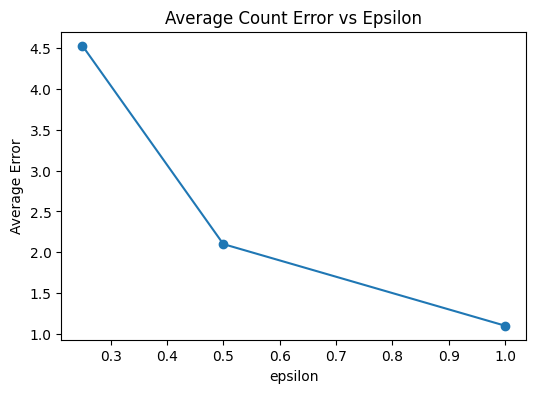

In [341]:
summary["count_error"].plot(
    marker="o",
    figsize=(6,4)
)

plt.title(
    "Average Count Error vs Epsilon"
)

plt.ylabel("Average Error")

plt.show()

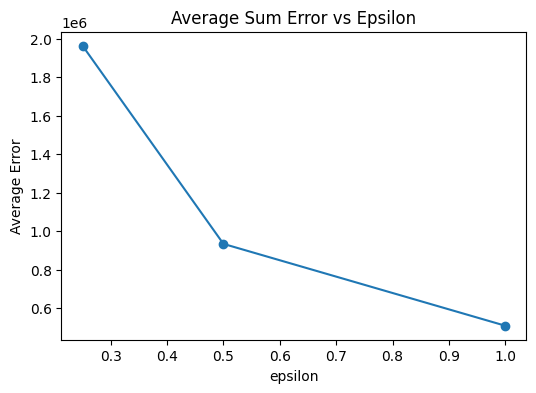

In [342]:
summary["sum_error"].plot(
    marker="o",
    figsize=(6,4)
)

plt.title(
    "Average Sum Error vs Epsilon"
)

plt.ylabel("Average Error")

plt.show()

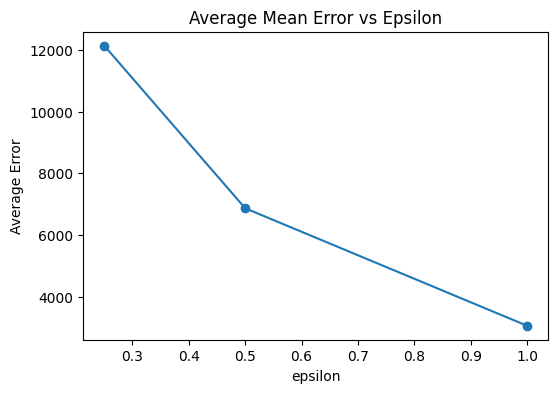

In [343]:
summary["mean_error"].plot(
    marker="o",
    figsize=(6,4)
)

plt.title(
    "Average Mean Error vs Epsilon"
)

plt.ylabel("Average Error")

plt.show()

In [344]:
original_count = len(account_table)

adjacent_table = account_table.iloc[:-1]

adjacent_count = len(adjacent_table)

difference = abs(
    original_count
    - adjacent_count
)

print("Original Count:", original_count)
print("Adjacent Count:", adjacent_count)
print("Difference:", difference)

assert difference <= 1

print("PASS: Sensitivity test")

Original Count: 157
Adjacent Count: 156
Difference: 1
PASS: Sensitivity test


In [345]:
request_release(
    "Counterfactual Query",
    epsilon=0.5,
    delta=0
)

DENY: Counterfactual Query
Privacy budget exceeded


False

In [346]:
print("Privacy Budget Ledger")

display(ledger)

print("Total Epsilon:", epsilon_total)
print("Total Delta:", delta_total)

assert epsilon_total <= 2.0
assert delta_total <= 1e-5

print("PASS: Budget constraints satisfied")

Privacy Budget Ledger


,Query,Mechanism,Epsilon,Delta
0,Account Count,Laplace,0.50,0.00000
1,Bounded Sum,Laplace,0.75,0.00000
2,Private Mean,Laplace,0.50,0.00000
3,Gaussian Declined Count,Gaussian,0.25,0.00001


Total Epsilon: 2.0
Total Delta: 1e-05
PASS: Budget constraints satisfied


In [347]:
post_processed_count = max(
    round(private_count),
    0
)

print(
    "Released Count:",
    post_processed_count
)

assert post_processed_count >= 0

print("PASS: Valid output domain")

Released Count: 156
PASS: Valid output domain


In [349]:
federated_table = account_table.copy()

federated_table["INSTITUTION"] = (
    federated_table["ACCOUNT"]
    .astype(int)
    % 3
)

federated_table["INSTITUTION"] = (
    federated_table["INSTITUTION"]
    .map({
        0: "Institution_A",
        1: "Institution_B",
        2: "Institution_C"
    })
)

federated_table.head()

,ACCOUNT,PRIMARY_CITY,PRIMARY_CHANNEL,TXN_COUNT,TOTAL_AMOUNT,DECLINE_FLAG,INSTITUTION
0,99000000001,Bloemfontein,ATM,4,191460,1,Institution_B
1,99000000002,East London,ATM,2,169577,0,Institution_C
2,99000000003,Johannesburg,ATM,3,39332,0,Institution_A
3,99000000004,Gqeberha,ECOM,2,19697,0,Institution_B
4,99000000005,Johannesburg,ECOM,7,549607,1,Institution_C


In [350]:
institution_counts = (
    federated_table["INSTITUTION"]
    .value_counts()
)

print("Accounts per Institution")

display(institution_counts)

Accounts per Institution


,count
INSTITUTION,
Institution_B,53
Institution_C,53
Institution_A,51


In [351]:
duplicates = (
    federated_table
    .groupby("ACCOUNT")
    ["INSTITUTION"]
    .nunique()
)

max_institutions = duplicates.max()

print(
    "Maximum Institutions per Account:",
    max_institutions
)

assert max_institutions == 1

print(
    "PASS: No account shared between institutions"
)

Maximum Institutions per Account: 1
PASS: No account shared between institutions


In [352]:
metadata_report = (
    federated_table
    .groupby("INSTITUTION")
    .agg({
        "ACCOUNT":"count",
        "DECLINE_FLAG":"mean"
    })
    .rename(
        columns={
            "ACCOUNT":"ACCOUNT_COUNT",
            "DECLINE_FLAG":"DECLINE_RATE"
        }
    )
)

display(metadata_report)

,ACCOUNT_COUNT,DECLINE_RATE
INSTITUTION,,
Institution_A,51,0.549020
Institution_B,53,0.603774
Institution_C,53,0.584906


In [353]:
central_decline_rate = (
    account_table["DECLINE_FLAG"]
    .mean()
)

print(
    "Central Benchmark:",
    round(central_decline_rate, 6)
)

Central Benchmark: 0.579618


In [354]:
site_stats = (
    federated_table
    .groupby("INSTITUTION")
    .agg(
        ACCOUNT_COUNT=("ACCOUNT", "count"),
        DECLINE_RATE=("DECLINE_FLAG", "mean")
    )
)

display(site_stats)

,ACCOUNT_COUNT,DECLINE_RATE
INSTITUTION,,
Institution_A,51,0.549020
Institution_B,53,0.603774
Institution_C,53,0.584906


In [355]:
naive_average = (
    site_stats["DECLINE_RATE"]
    .mean()
)

print(
    "Naive Site Average:",
    round(naive_average, 6)
)

Naive Site Average: 0.579233


In [356]:
weighted_average = (
    (
        site_stats["ACCOUNT_COUNT"]
        *
        site_stats["DECLINE_RATE"]
    ).sum()
    /
    site_stats["ACCOUNT_COUNT"].sum()
)

print(
    "Weighted Federated Average:",
    round(weighted_average, 6)
)


Weighted Federated Average: 0.579618


In [357]:
comparison = pd.DataFrame({

    "Method":[
        "Central Benchmark",
        "Naive Site Average",
        "Weighted Federated Average"
    ],

    "Value":[
        central_decline_rate,
        naive_average,
        weighted_average
    ]

})

display(comparison)

,Method,Value
0,Central Benchmark,0.579618
1,Naive Site Average,0.579233
2,Weighted Federated Average,0.579618


In [358]:
A = 51
B = 53
C = 53

true_total = A + B + C

print("True Aggregate:", true_total)

True Aggregate: 157


In [359]:
import numpy as np

np.random.seed(42)

r1 = np.random.randint(100, 500)
r2 = np.random.randint(100, 500)
r3 = -(r1 + r2)

print("Mask 1:", r1)
print("Mask 2:", r2)
print("Mask 3:", r3)

print(
    "Mask Check:",
    r1 + r2 + r3
)

Mask 1: 202
Mask 2: 448
Mask 3: -650
Mask Check: 0


In [360]:
masked_A = A + r1
masked_B = B + r2
masked_C = C + r3

print("Institution A sends:", masked_A)
print("Institution B sends:", masked_B)
print("Institution C sends:", masked_C)

Institution A sends: 253
Institution B sends: 501
Institution C sends: -597


In [361]:
secure_sum = (
    masked_A
    + masked_B
    + masked_C
)

print(
    "Secure Aggregate:",
    secure_sum
)

print(
    "True Aggregate:",
    true_total
)

assert secure_sum == true_total

print(
    "PASS: Mask cancellation verified"
)

Secure Aggregate: 157
True Aggregate: 157
PASS: Mask cancellation verified


In [362]:
trace = pd.DataFrame({

    "Institution":[
        "A",
        "B",
        "C"
    ],

    "Local Value":[
        A,
        B,
        C
    ],

    "Mask":[
        r1,
        r2,
        r3
    ],

    "Masked Message":[
        masked_A,
        masked_B,
        masked_C
    ]

})

display(trace)

,Institution,Local Value,Mask,Masked Message
0,A,51,202,253
1,B,53,448,501
2,C,53,-650,-597


In [363]:
# Institution C drops out

failed_secure_sum = (
    masked_A
    + masked_B
)

print(
    "Coordinator Result After Drop-Out:",
    failed_secure_sum
)

print(
    "True Aggregate:",
    true_total
)

print(
    "Error:",
    failed_secure_sum - true_total
)

Coordinator Result After Drop-Out: 754
True Aggregate: 157
Error: 597


In [364]:
comparison = pd.DataFrame({

    "Scenario":[
        "All Institutions Present",
        "Institution C Drops Out"
    ],

    "Result":[
        secure_sum,
        failed_secure_sum
    ]

})

display(comparison)

,Scenario,Result
0,All Institutions Present,157
1,Institution C Drops Out,754


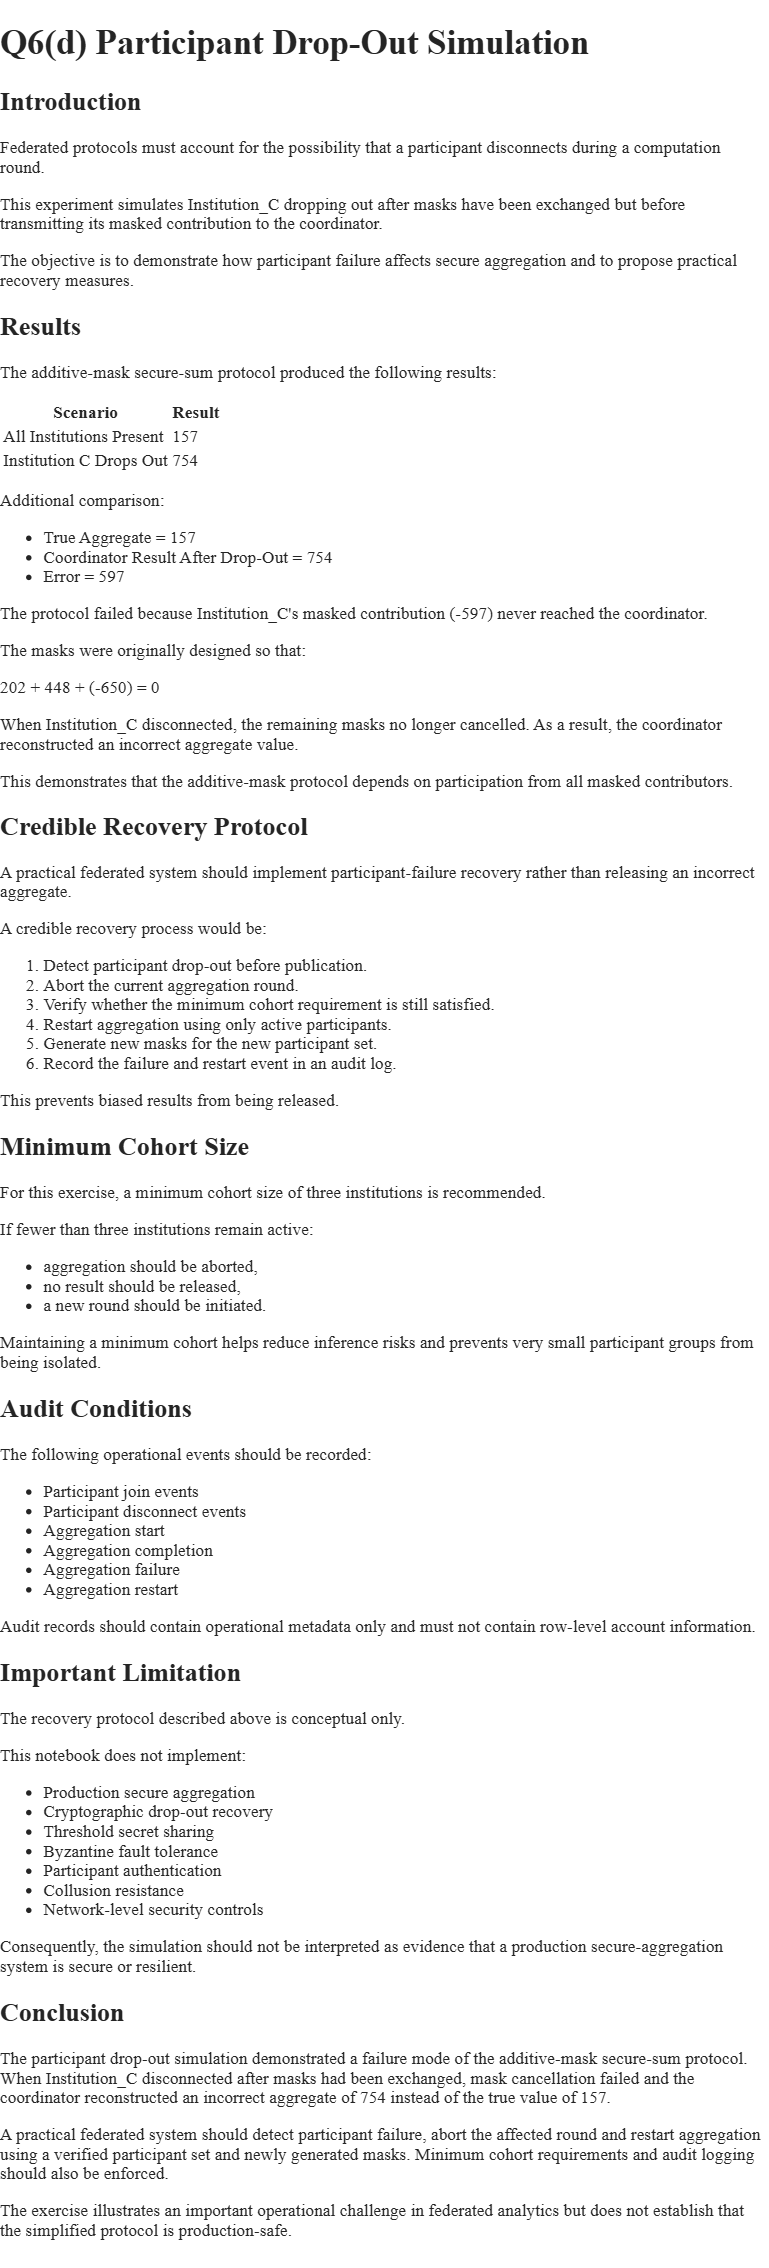

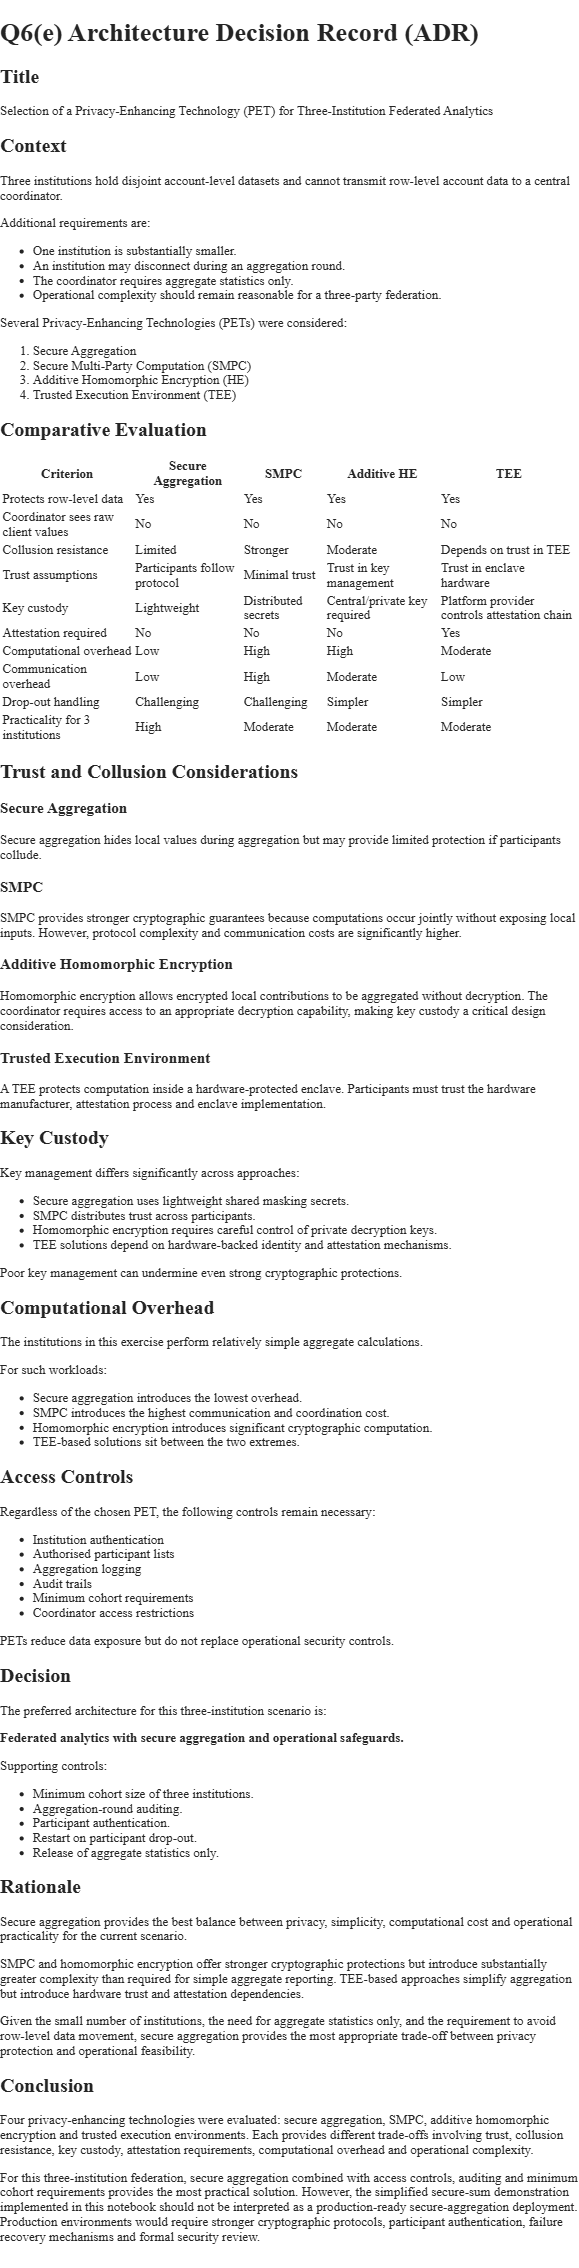

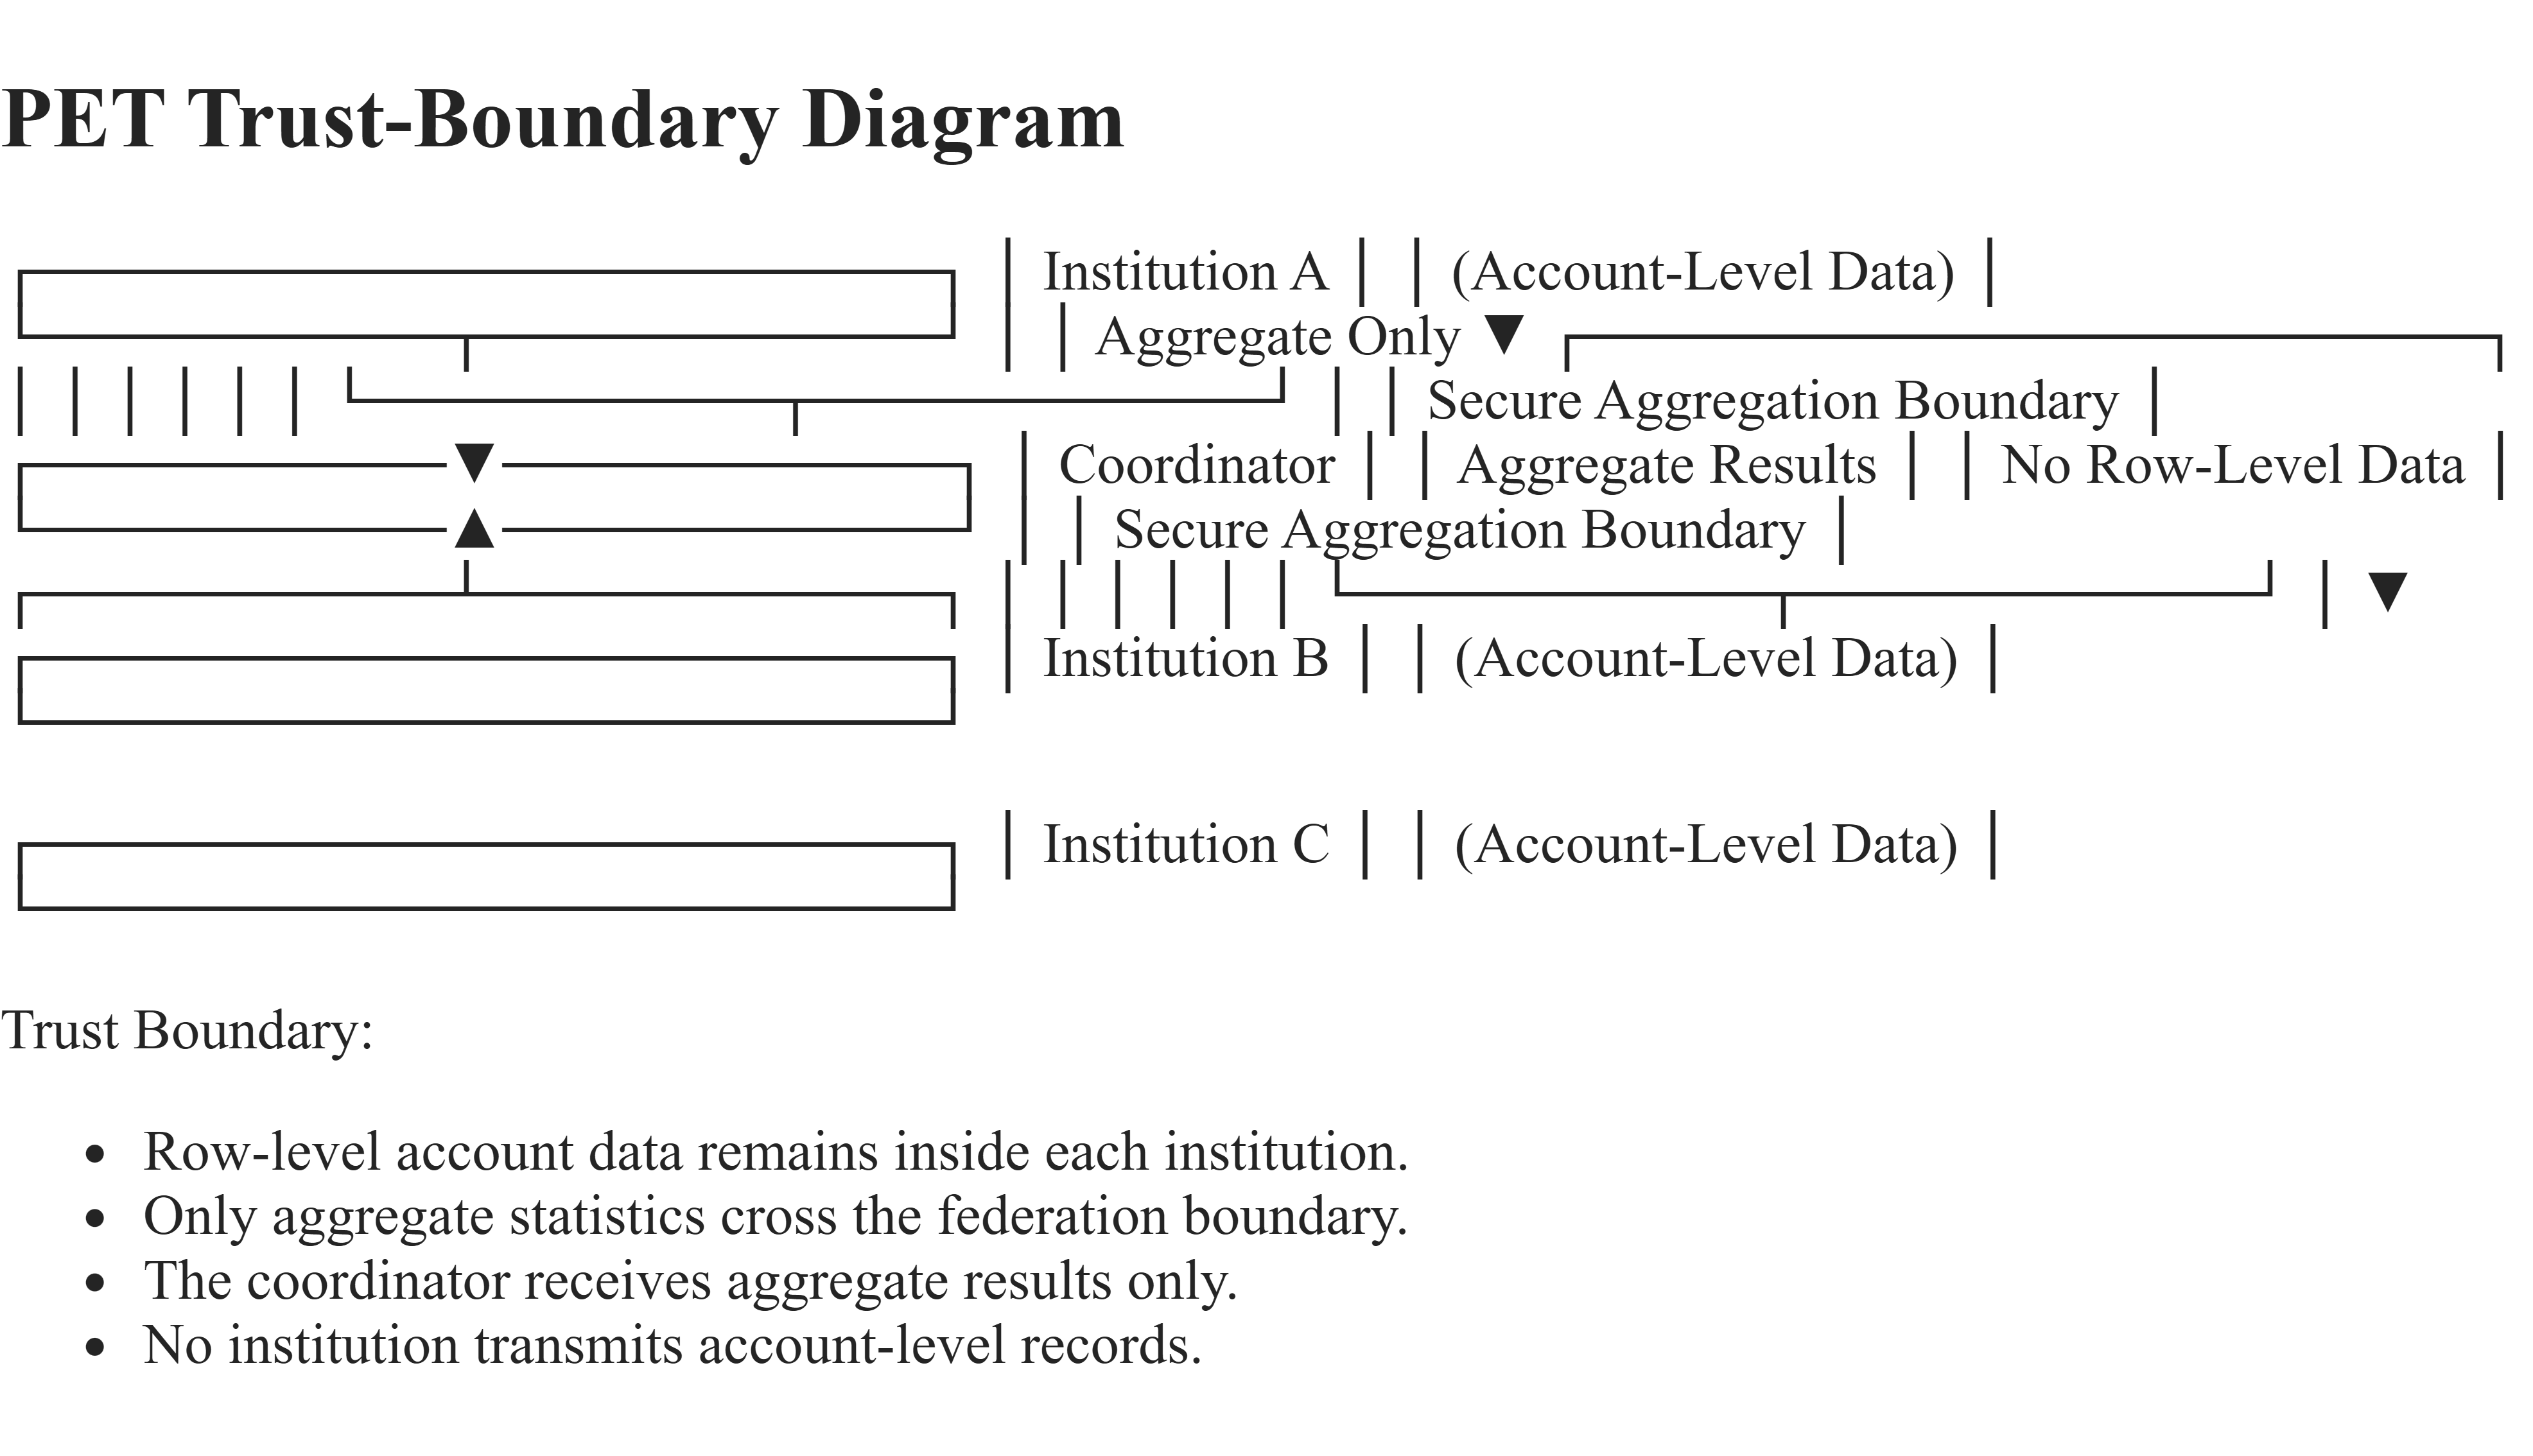

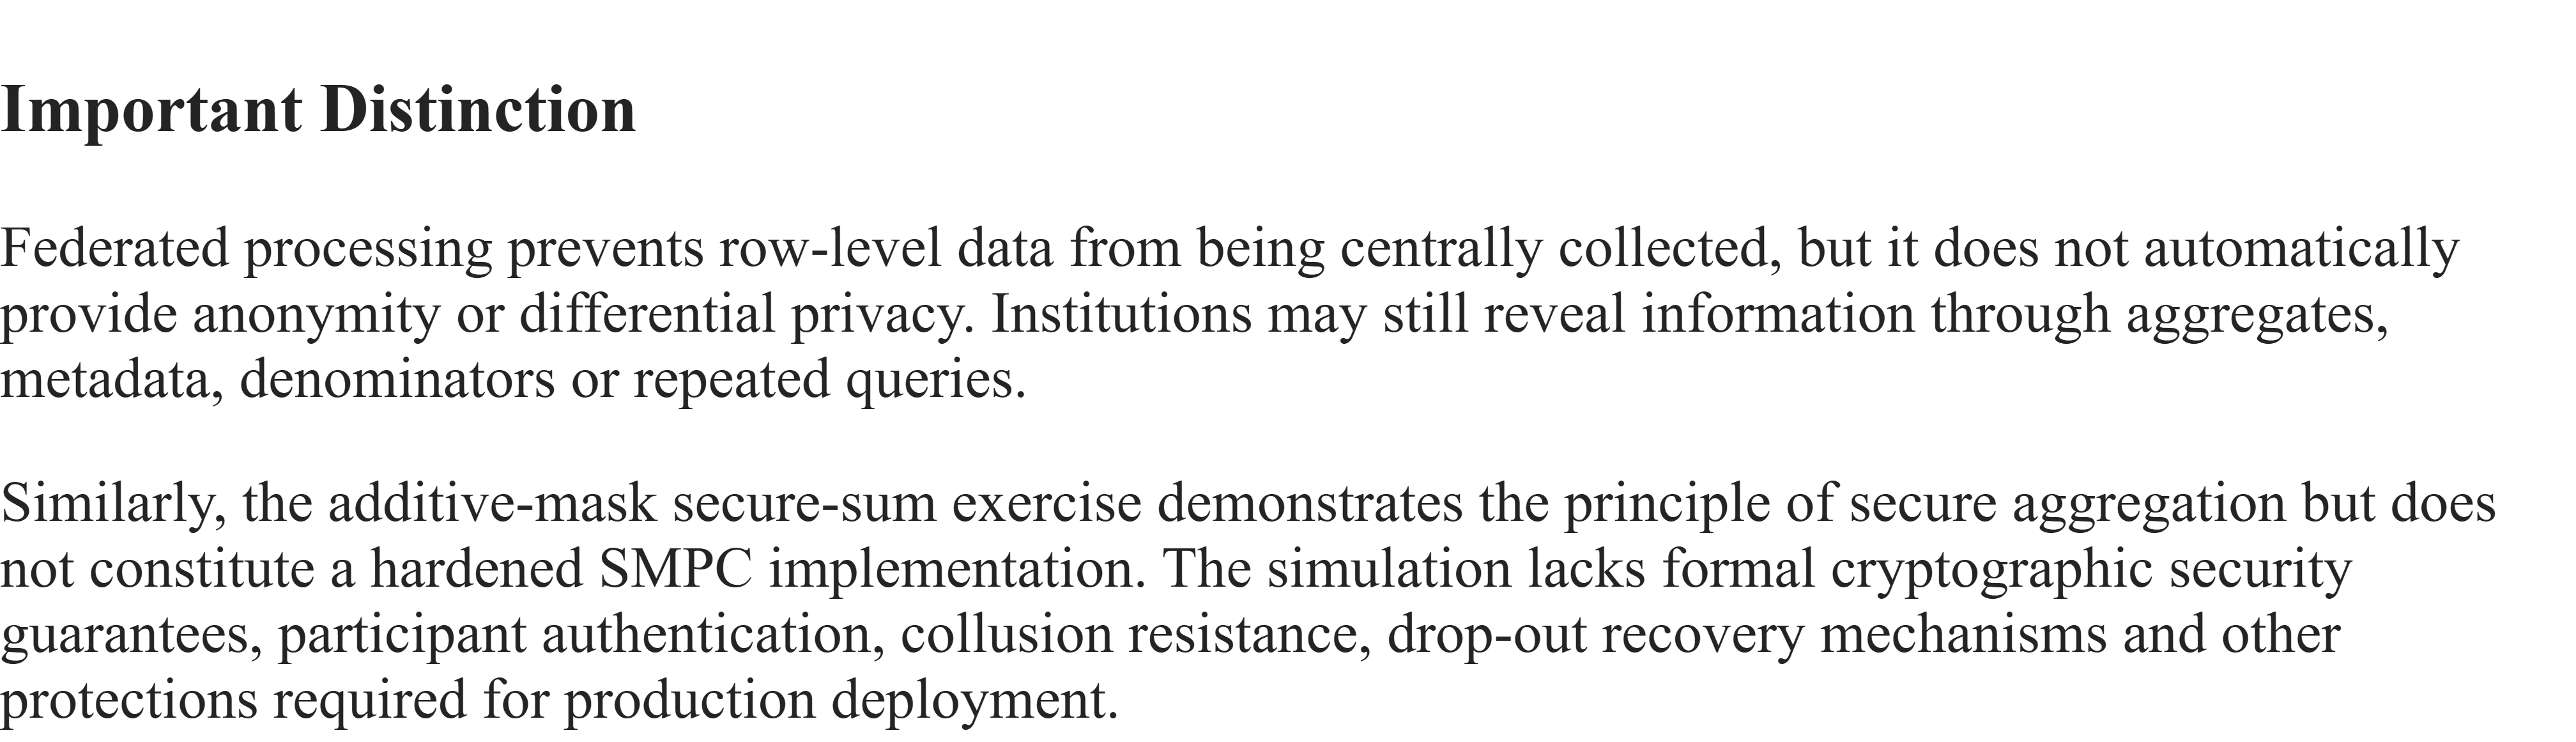